# DressMe — Objectif 4 : Détection des pièces manquantes · édition « Atelier »

**Objectif du cahier des charges :** *Wardrobe gap detection — identifier les pièces manquantes qui maximiseraient le nombre de combinaisons possibles, utile pour des achats stratégiques.*

**Idée de base :** une pièce vaut l'achat si elle **crée beaucoup de nouvelles tenues** avec ce que l'on possède déjà. On apprend (1) quelles pièces vont ensemble, (2) on compte les tenues réalisables, (3) on calcule pour chaque article le **nombre de tenues qu'il ajoute**.

**Ce que cette édition ajoute (au-delà du simple comptage)**

| Apport | Question à laquelle il répond | Section |
|---|---|---|
| **Radiographie** | Quelles pièces que *je possède déjà* ne créent aucune tenue (poids mort) ? | 9.b |
| **Lentille persona** | Le même manque donne-t-il la même réponse à Amine (prix), Yasmine (efficacité) et Sami (signature) ? | 9.c |
| **Pièce fantôme** | À quoi ressemble la pièce *idéale* ? Le modèle la décrit et retrouve de vrais articles proches, sans tester tout le catalogue. | 9.d |
| **Saisons** | Où est le trou : été ou hiver ? (contexte tunisien) | 9.e |
| **Robustesse** | Le classement tient-il si on change le seuil τ ? | 9.f |
| **Juge indépendant** | Le panier reste-t-il bon jugé par un *second* modèle (et non par celui qui l'a construit) ? | 9.g |
| **Export application** | `gap_report.json`, au format attendu par l'écran « Gaps » de l'interface. | 10.b |

**Données :** Re-PolyVore (20 catégories). **Elles restent en ligne** : le zip est hébergé sur Hugging Face (ou Kaggle) et copié directement sur le disque du serveur Colab. Rien n'est téléchargé sur ton ordinateur (voir section 1).

**Pipeline :** 1 données en ligne → 2 lecture des tenues → 3 embeddings FashionCLIP (cache) → 4 catégories → emplacements → 5 compatibilité → 6 compteur de combinaisons → 7 gain / panier glouton → 8 évaluation → **9.b à 9.g apports « Atelier »** → 10 export.


## 0. Configuration

In [19]:
import os, re, json, math, random, time, shutil, zipfile, warnings
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED)

SMOKE_TEST = os.environ.get('DRESSME_SMOKE', '0') == '1'   # test synthétique
FORCE_REEMBED = False            # True pour recalculer les embeddings
MODEL_NAME = 'patrickjohncyh/fashion-clip'
ZIP_NAME = 'Re-PolyVore.zip'
PCA_DIM = 128                    # dimension réduite pour le modèle de compatibilité
MAX_TRAIN_PAIRS = 200_000        # paires (positives + négatives) pour entraîner la compatibilité
N_WARDROBES = 400                # garde-robes simulées pour l'évaluation
OUTFITS_PER_WARDROBE = 4         # tenues réunies par garde-robe simulée
N_CANDIDATES = 100               # 1 article caché + 99 candidats
N_CURVE = 150                    # garde-robes pour la courbe « combinaisons vs achats »
K_BUY = 5                        # nombre d'achats dans le panier
if SMOKE_TEST:
    MAX_TRAIN_PAIRS, N_WARDROBES, N_CANDIDATES, N_CURVE, PCA_DIM = 20_000, 60, 40, 30, 32

# ---------------- Où sont les données ? ----------------
try:
    from google.colab import userdata
    has_hf_token = userdata.get('HF_TOKEN') is not None
except Exception:
    has_hf_token = os.environ.get('HF_TOKEN') is not None

# Si nous détectons un environnement Kaggle avec le dataset connecté, on force la source à 'kaggle'
IN_KAGGLE = False
if IN_KAGGLE:
    DATA_SOURCE = 'kaggle'
else:
    DATA_SOURCE = os.environ.get('DRESSME_SOURCE', 'hf' if has_hf_token else 'drive')

HF_REPO = os.environ.get('DRESSME_HF_REPO', 'TON_COMPTE/dressme-repolyvore')
HF_ZIP_PATH = 'Re-PolyVore.zip'
KAGGLE_DIR = '/kaggle/input/re-polyvore'
PUSH_OUTPUTS_TO_HF = has_hf_token
USD_TND = 3.1
if SMOKE_TEST: DATA_SOURCE = 'drive'

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and DATA_SOURCE == 'drive' and not SMOKE_TEST:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception as e:
        print("Impossible de monter le Google Drive :", e)

if SMOKE_TEST:
    DRIVE_DIR = Path('./dressme_obj4_smoke'); WORK = DRIVE_DIR / 'obj4'; DATA_DIR = DRIVE_DIR / 'data'
elif DATA_SOURCE == 'kaggle':
    DRIVE_DIR = Path('/kaggle/working'); WORK = DRIVE_DIR / 'obj4'; DATA_DIR = Path('/kaggle/input/re-polyvore')
elif DATA_SOURCE == 'drive' and IN_COLAB:
    DRIVE_DIR = Path('/content/drive/MyDrive/DressMe'); WORK = Path('/content/dressme_obj4'); DATA_DIR = Path('/content/repolyvore')
elif IN_COLAB:
    DRIVE_DIR = Path('/content'); WORK = DRIVE_DIR / 'dressme_obj4'; DATA_DIR = DRIVE_DIR / 'repolyvore'
else:
    DRIVE_DIR = Path('.'); WORK = Path('./dressme_obj4'); DATA_DIR = WORK / 'data'

FIG, ART = WORK / 'figures', WORK / 'artifacts'
for p in (WORK, FIG, ART): p.mkdir(parents=True, exist_ok=True)
if DATA_SOURCE != 'kaggle':
    DATA_DIR.mkdir(parents=True, exist_ok=True)

ZIP_CANDIDATES = [
    DRIVE_DIR / ZIP_NAME,
    Path('/content') / ZIP_NAME,
    Path(ZIP_NAME),
    Path.home() / 'Downloads' / ZIP_NAME
]

# ---------------- Hugging Face : jeton, récupération du cache ----------------
def hf_token():
    try:
        from google.colab import userdata
        return userdata.get('HF_TOKEN')
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        return os.environ.get('HF_TOKEN')

def hf_pull(name):
    if SMOKE_TEST or DATA_SOURCE != 'hf': return False
    try:
        from huggingface_hub import hf_hub_download
        p = hf_hub_download(HF_REPO, f'obj4/artifacts/{name}', repo_type='dataset', token=hf_token())
        shutil.copy(p, ART / name); print('Cache récupéré depuis Hugging Face :', name); return True
    except Exception:
        return False

def hf_push(path, dest):
    if SMOKE_TEST or DATA_SOURCE != 'hf' or not PUSH_OUTPUTS_TO_HF: return
    try:
        from huggingface_hub import HfApi
        HfApi(token=hf_token()).upload_file(path_or_fileobj=str(path), path_in_repo=dest, repo_id=HF_REPO, repo_type='dataset')
        print('Envoyé sur Hugging Face :', dest)
    except Exception as e:
        print('Envoi vers Hugging Face ignoré :', e)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches='tight'); plt.show(); plt.close()

def l2n(X):
    X = np.asarray(X, dtype=np.float32)
    return X / np.clip(np.linalg.norm(X, axis=-1, keepdims=True), 1e-8, None)

print('Source :', DATA_SOURCE, '| sorties :', WORK.resolve(), '| données :', DATA_DIR.resolve(), '| smoke test :', SMOKE_TEST)

Source : hf | sorties : /content/dressme_obj4 | données : /content/repolyvore | smoke test : False


### 0.b Données synthétiques (uniquement si `SMOKE_TEST`)
Ne fait rien en exécution normale. En mode test, fabrique un petit `Re-PolyVore.zip` factice pour vérifier que toutes les cellules tournent.

In [20]:
if SMOKE_TEST:
    from PIL import Image
    rs = np.random.RandomState(0)
    DIM = 48; N_STYLE = 6
    CATS_S = ['Tops', 'Skirts', 'Pants', 'Outwear', 'Dresses', 'Jumpsuits', 'Shoes', 'Bags', 'Earrings', 'Necklaces', 'Hats', 'Hair wear']
    style_dir = rs.normal(size=(N_STYLE, DIM)); cat_dir = {c: 1.5 * rs.normal(size=DIM) for c in CATS_S}
    LATENT = {}
    zpath = DRIVE_DIR / ZIP_NAME
    with zipfile.ZipFile(zpath, 'w') as zf:
        oid = 1000
        for split, n in [('train', 700), ('valid', 120), ('test', 300)]:
            for _ in range(n):
                s = rs.randint(N_STYLE); oid += 1
                if rs.rand() < 0.7: cats = ['Tops', rs.choice(['Skirts', 'Pants']), 'Shoes']
                else: cats = [rs.choice(['Dresses', 'Jumpsuits']), 'Shoes']
                cats += [c for c in ['Outwear', 'Bags', 'Earrings', 'Necklaces', 'Hats', 'Hair wear'] if rs.rand() < 0.35]
                for k, c in enumerate(cats, 1):
                    fname = f'{c}_{k}.jpg' if rs.rand() > 0.05 else f'{k}.jpg'   # 5 % sans catégorie -> zéro-shot
                    rel = f'Re-PolyVore/{split}/{oid}/{fname}'
                    v = style_dir[s] + cat_dir[c] + 0.9 * rs.normal(size=DIM)
                    LATENT[rel] = (v / np.linalg.norm(v)).astype(np.float32)
                    buf = __import__('io').BytesIO()
                    Image.fromarray(rs.randint(0, 255, (8, 8, 3), dtype=np.uint8)).save(buf, 'JPEG')
                    zf.writestr(rel, buf.getvalue())
    print('Zip synthétique créé :', zpath, f'({len(LATENT)} images)')

## 1. Données en ligne (zéro téléchargement sur ton PC)

Le zip fait 3,2 Go. Au lieu de le télécharger chez toi, on le **garde en ligne** et le serveur le récupère directement :

| `DATA_SOURCE` | Où est le zip | Ce qu'il faut faire |
|---|---|---|
| **`'hf'`** (recommandé) | Dépôt *dataset* privé sur Hugging Face | 1) créer un compte gratuit et un jeton d'accès (*Settings → Access Tokens*, droit « write ») ; 2) dans Colab, icône 🔑 **Secrets** → ajouter `HF_TOKEN` ; 3) mettre ton dépôt dans `HF_REPO` (cellule 0) ; 4) lancer **une seule fois** la cellule d'envoi ci-dessous. |
| `'kaggle'` | Dataset attaché au notebook Kaggle | *Add Input* → ton dataset. Rien à copier : Kaggle le monte en lecture seule. |
| `'drive'` | Google Drive | Ancien mode (copie Drive → Colab). |

**Pourquoi Hugging Face ?** Gratuit, fichiers volumineux acceptés, dépôt privé, et **tes coéquipiers utilisent le même dépôt** (les embeddings, le modèle et le JSON pour l'application y sont aussi envoyés dans `obj4/`).

**Envoi sans passer par ton PC :** le zip part *de Drive (ou d'un lien de partage) vers Hugging Face*, de serveur à serveur.


In [21]:
# Cellule à exécuter UNE SEULE FOIS. Ensuite : ONE_TIME_UPLOAD = False
#ONE_TIME_UPLOAD = False
UPLOAD_FROM = 'drive'      # 'drive' : le zip est dans Mon Drive/DressMe/ | 'url' : lien de partage Google Drive (gdown)
SOURCE_URL = ''            # lien de partage si UPLOAD_FROM == 'url'

if ONE_TIME_UPLOAD and not SMOKE_TEST:
    from huggingface_hub import HfApi
    api = HfApi(token=hf_token())
    api.create_repo(HF_REPO, repo_type='dataset', private=True, exist_ok=True)
    if UPLOAD_FROM == 'url':
        import subprocess; subprocess.run(['pip', '-q', 'install', 'gdown'], check=True)
        import gdown; src_zip = gdown.download(SOURCE_URL, f'/content/{ZIP_NAME}', quiet=False, fuzzy=True)
    else:
        from google.colab import drive; drive.mount('/content/drive')
        src_zip = f'/content/drive/MyDrive/DressMe/{ZIP_NAME}'
    print('Envoi vers Hugging Face (quelques minutes)...', flush=True)
    api.upload_file(path_or_fileobj=src_zip, path_in_repo=HF_ZIP_PATH, repo_id=HF_REPO, repo_type='dataset')
    print('Terminé : https://huggingface.co/datasets/' + HF_REPO)
else:
    print('Envoi désactivé (ONE_TIME_UPLOAD = False).')


Envoi désactivé (ONE_TIME_UPLOAD = False).


In [22]:
import os
from google.colab import userdata

try:
    # Récupération sécurisée des identifiants depuis les secrets Colab (icône 🔑)
    kaggle_username = userdata.get('KAGGLE_USERNAME')
    kaggle_key = userdata.get('KAGGLE_KEY')

    if kaggle_username and kaggle_key:
        # Définition des variables d'environnement lues directement par l'outil CLI Kaggle
        os.environ['KAGGLE_USERNAME'] = kaggle_username
        os.environ['KAGGLE_KEY'] = kaggle_key
        print("Clés d'API Kaggle configurées avec succès depuis vos secrets Colab !")
    else:
        print("⚠️ Attention : Les secrets 'KAGGLE_USERNAME' ou 'KAGGLE_KEY' semblent vides ou non configurés dans l'onglet 🔑.")
except Exception as e:
    print("Erreur lors de la lecture des secrets Colab :", e)
    print("Assurez-vous d'avoir créé 'KAGGLE_USERNAME' et 'KAGGLE_KEY' dans l'onglet 🔑 et d'avoir autorisé l'accès pour ce notebook.")

Clés d'API Kaggle configurées avec succès depuis vos secrets Colab !


In [23]:
import subprocess
import zipfile
from pathlib import Path

# 1. Télécharger le dataset en utilisant l'API de Kaggle
print("Téléchargement du dataset Re-Polyvore en cours...")
subprocess.run(["kaggle", "datasets", "download", "-d", "nastaranganji/re-polyvore", "-p", "/content"], check=True)

# 2. Dézipper le fichier téléchargé
zip_path = Path("/content/re-polyvore.zip")
extract_path = Path("/content/repolyvore")

if zip_path.exists():
    print("Extraction des données...")
    extract_path.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    # Créer un fichier témoin pour indiquer que l'extraction s'est bien déroulée
    (extract_path / '.extraction_ok').write_text('ok')
    print(f"Extraction réussie dans {extract_path} !")
else:
    print("Erreur : Le fichier zip n'a pas été trouvé après le téléchargement.")

Téléchargement du dataset Re-Polyvore en cours...
Extraction des données...
Extraction réussie dans /content/repolyvore !


### 1.b Diagnostic de la structure
Affiche les types de fichiers, l'arborescence et des exemples de chemins. **Si la lecture automatique (section 2) échoue, c'est cette sortie qu'il faut regarder.**

In [24]:
ALL_FILES = []
for dp, dn, fn in os.walk(DATA_DIR):
    dn[:] = [d for d in dn if not d.startswith('__MACOSX') and not d.startswith('.')]
    for f in fn:
        if not f.startswith('.'): ALL_FILES.append(Path(dp) / f)
REL = [p.relative_to(DATA_DIR).as_posix() for p in ALL_FILES]
ext = Counter(PurePosixPath(r).suffix.lower() for r in REL)
print('Fichiers :', len(REL), '| extensions :', ext.most_common(8))
tree = Counter('/'.join(PurePosixPath(r).parts[:2]) for r in REL)
print('\nDossiers (2 niveaux), 15 plus gros :')
for d, c in tree.most_common(15): print(f'  {d:60s} {c:>8d} fichiers')
IMGS_REL = [r for r in REL if r.lower().endswith(IMG_EXT)]
print('\nExemples d’images :'); [print('  ', r) for r in IMGS_REL[:: max(1, len(IMGS_REL) // 8)][:8]]
META = [p for p in ALL_FILES if p.suffix.lower() in ('.json', '.csv', '.txt')]
print('\nFichiers de métadonnées :'); [print(f'   {p.relative_to(DATA_DIR)}  ({p.stat().st_size / 1e6:.1f} Mo)') for p in META[:20]]

Fichiers : 126949 | extensions : [('.jpg', 126928), ('.ini', 20), ('.lnk', 1)]

Dossiers (2 niveaux), 15 plus gros :
  Re-PolyVore/bag                                                 21270 fichiers
  Re-PolyVore/shoes                                               20136 fichiers
  Re-PolyVore/top                                                 19398 fichiers
  Re-PolyVore/outwear                                             10170 fichiers
  Re-PolyVore/pants                                                8958 fichiers
  Re-PolyVore/dress                                                7480 fichiers
  Re-PolyVore/eyewear                                              6681 fichiers
  Re-PolyVore/earrings                                             5509 fichiers
  Re-PolyVore/skirt                                                5308 fichiers
  Re-PolyVore/bracelet                                             5175 fichiers
  Re-PolyVore/necklace                                             4665 f

[]

## 2. Lecture automatique des tenues
Deux formats sont reconnus :
- **A. Format Maryland (JSON)** : fichiers `*_no_dup.json` avec `set_id`, `items`, `categoryid` (+ prix, nom). Images dans `<set_id>/<index>.jpg`.
- **B. Format dossiers** : une image par article ; la **catégorie** est lue dans le chemin (nom de dossier ou de fichier contenant l'une des 20 catégories), la **tenue** est le dossier parent (ou le préfixe du nom de fichier si le parent est une catégorie), le **split** est lu dans le chemin (`train`, `valid`, `test`) ou tiré au hasard (80/10/10 par tenue).

Les articles dont la catégorie reste inconnue seront classés en zéro-shot par FashionCLIP (section 4). Si aucun format ne convient, remplir `CUSTOM_PARSE` (fonction qui renvoie le même DataFrame).

In [25]:
CATS20 = ['Tops', 'Skirts', 'Pants', 'Outwear', 'Dresses', 'Jumpsuits', 'Shoes', 'Bags', 'Earrings', 'Necklaces',
          'Rings', 'Bracelets', 'Watches', 'Hats', 'Eyewear', 'Gloves', 'Legwear', 'Neckwear', 'Hair wear', 'Brooch']
def norm(s): return re.sub(r'[^a-z]', '', str(s).lower())
ALIASES = {norm(c): c for c in CATS20}
ALIASES.update({'top': 'Tops', 'skirt': 'Skirts', 'pant': 'Pants', 'trousers': 'Pants', 'jeans': 'Pants',
                'outerwear': 'Outwear', 'outwears': 'Outwear', 'coats': 'Outwear', 'jackets': 'Outwear',
                'dress': 'Dresses', 'jumpsuit': 'Jumpsuits', 'shoe': 'Shoes', 'bag': 'Bags', 'earring': 'Earrings',
                'necklace': 'Necklaces', 'ring': 'Rings', 'bracelet': 'Bracelets', 'watch': 'Watches', 'hat': 'Hats',
                'glasses': 'Eyewear', 'sunglasses': 'Eyewear', 'glove': 'Gloves', 'hairwear': 'Hair wear',
                'brooches': 'Brooch', 'scarf': 'Neckwear', 'scarves': 'Neckwear', 'socks': 'Legwear', 'tights': 'Legwear'})
SPLITS = {'train': 'train', 'training': 'train', 'valid': 'valid', 'val': 'valid', 'validation': 'valid',
          'test': 'test', 'testing': 'test'}

def cat_of_component(comp):
    n = norm(comp)
    if n in ALIASES: return ALIASES[n]
    toks = [norm(t) for t in re.split(r'[_\-\s.]+', comp) if norm(t)]
    for a, b in zip(toks, toks[1:]):
        if a + b in ALIASES: return ALIASES[a + b]
    for t in toks:
        if t in ALIASES: return ALIASES[t]
    return None

def parse_folder_layout(rels):
    rows = []
    for rel in rels:
        pp = PurePosixPath(rel); parts = pp.parts; stem = pp.stem
        cat = None
        for comp in list(parts[:-1]) + [stem]:
            cat = cat_of_component(comp) or cat
        split = next((SPLITS[norm(c)] for c in parts[:-1] if norm(c) in SPLITS), None)
        parent = parts[-2] if len(parts) >= 2 else ''
        if parent and cat_of_component(parent) is None and norm(parent) not in SPLITS:
            outfit = '/'.join(parts[:-1])
        else:
            toks = [t for t in re.split(r'[_\-\s.]+', stem) if t and cat_of_component(t) is None]
            outfit = '/'.join([c for c in parts[:-1] if cat_of_component(c) is None] + [toks[0]]) if len(toks) >= 2 else None
        rows.append(dict(item_id=rel, outfit_id=outfit, split=split, path=str(DATA_DIR / rel), cat=cat, name='', price=np.nan))
    return pd.DataFrame(rows)

FINE_RULES = [('Eyewear', r'sunglass|eyewear|eyeglass|glasses'), ('Watches', r'watch'), ('Earrings', r'earring'),
    ('Necklaces', r'necklace|pendant'), ('Bracelets', r'bracelet|bangle|cuff'), ('Rings', r'\bring'), ('Brooch', r'brooch'),
    ('Bags', r'bag|clutch|tote|purse|backpack|wallet|satchel|pouch|hobo|crossbody'),
    ('Shoes', r'shoe|pump|sandal|boot|sneaker|heel|flat|loafer|oxford|wedge|mule|slipper|espadrille|clog|trainer'),
    ('Jumpsuits', r'jumpsuit|romper|playsuit|overall'), ('Dresses', r'dress|gown'),
    ('Outwear', r'jacket|coat|blazer|parka|poncho|cape|trench|vest|outerwear'), ('Skirts', r'skirt'),
    ('Legwear', r'sock|tights|hosiery|stocking'), ('Pants', r'jean|pant|trouser|short|legging|jogger|culotte'),
    ('Tops', r'top|tee|t-shirt|shirt|blouse|sweater|cardigan|tank|cami|tunic|sweatshirt|hoodie|pullover|bodysuit|polo|knit'),
    ('Hats', r'\bhat|\bcap\b|beanie|beret|fedora|visor'), ('Gloves', r'glove|mitten'),
    ('Neckwear', r'scar[fv]|\btie\b|neck'), ('Hair wear', r'hair|headband')]
FINE_RE = [(c, re.compile(p, re.I)) for c, p in FINE_RULES]
def cat_of_fine(text):
    for c, rx in FINE_RE:
        if rx.search(str(text)): return c
    return None

def parse_maryland(json_files):
    img_dirs = defaultdict(set)
    for r in IMGS_REL:
        pp = PurePosixPath(r)
        if len(pp.parts) >= 2: img_dirs[pp.parts[-2]].add(pp.name)
    cat_name = {}
    for p in META:
        if p.name == 'category_id.txt':
            for line in open(p, encoding='utf-8', errors='ignore'):
                q = line.strip().split(maxsplit=1)
                if len(q) == 2 and q[0].isdigit(): cat_name[int(q[0])] = q[1]
    base = {PurePosixPath(r).parts[-2] + '/' + PurePosixPath(r).name: r for r in IMGS_REL if len(PurePosixPath(r).parts) >= 2}
    rows = []
    for jf in json_files:
        split = next((v for k, v in SPLITS.items() if jf.name.lower().startswith(k)), None)
        for o in json.load(open(jf, encoding='utf-8')):
            sid = str(o.get('set_id'))
            for it in o.get('items', []):
                idx = it.get('index'); m = re.search(r'tid=(\d+)', str(it.get('image', '')))
                rel = base.get(f'{sid}/{idx}.jpg') or base.get(f'{sid}/{idx}.png')
                cid = it.get('categoryid'); fine = cat_name.get(int(cid), '') if str(cid).isdigit() else ''
                name = str(it.get('name', '') or '')
                price = pd.to_numeric(pd.Series([it.get('price')]), errors='coerce').iloc[0]
                rows.append(dict(item_id=m.group(1) if m else f'{sid}_{idx}', outfit_id=f'{split}/{sid}', split=split,
                                 path=str(DATA_DIR / rel) if rel else '', cat=cat_of_fine(fine) or cat_of_fine(name),
                                 name=name, price=price if price == price and price > 0 else np.nan))
    return pd.DataFrame(rows)

CUSTOM_PARSE = None   # ex. : def CUSTOM_PARSE(): return pd.DataFrame(...) avec les colonnes ci-dessus

JSONS = [p for p in META if p.name.endswith('_no_dup.json')]
if CUSTOM_PARSE is not None:
    raw = CUSTOM_PARSE(); FORMAT = 'personnalisé'
elif JSONS:
    raw = parse_maryland(JSONS); FORMAT = 'A (Maryland JSON)'
    if (raw['path'] != '').mean() < 0.3 and IMGS_REL:
        print('Peu d’images reliées au JSON -> format dossiers'); raw = parse_folder_layout(IMGS_REL); FORMAT = 'B (dossiers)'
else:
    raw = parse_folder_layout(IMGS_REL); FORMAT = 'B (dossiers)'
print('Format détecté :', FORMAT)

raw = raw[raw['outfit_id'].notna()].copy()
assert len(raw) > 0, "Aucune tenue reconnue : regarde le diagnostic 1.b et remplis CUSTOM_PARSE."
size = raw.groupby('outfit_id').size()
print(f"Tenues : {len(size)} | articles : {len(raw)} | articles par tenue (médiane) : {size.median():.0f}")
assert size.median() >= 2, ("Les tenues reconnues n'ont qu'un article : la structure n'est pas celle attendue. "
                            "Regarde le diagnostic 1.b et remplis CUSTOM_PARSE.")
print('Catégorie lue dans les données :', f"{raw['cat'].notna().mean():.1%}", '| split lu :', f"{raw['split'].notna().mean():.1%}")
display(raw.head())

Format détecté : B (dossiers)
Tenues : 31333 | articles : 126652 | articles par tenue (médiane) : 4
Catégorie lue dans les données : 100.0% | split lu : 0.0%


,item_id,outfit_id,split,path,cat,name,price
0,Re-PolyVore/shoes/72949213_3.jpg,Re-PolyVore/72949213,None,/content/repolyvore/Re-PolyVore/shoes/72949213...,Shoes,,NaN
1,Re-PolyVore/shoes/212049592_3.jpg,Re-PolyVore/212049592,None,/content/repolyvore/Re-PolyVore/shoes/21204959...,Shoes,,NaN
2,Re-PolyVore/shoes/193399471_3.jpg,Re-PolyVore/193399471,None,/content/repolyvore/Re-PolyVore/shoes/19339947...,Shoes,,NaN
3,Re-PolyVore/shoes/191757267_4.jpg,Re-PolyVore/191757267,None,/content/repolyvore/Re-PolyVore/shoes/19175726...,Shoes,,NaN
4,Re-PolyVore/shoes/100669789_5.jpg,Re-PolyVore/100669789,None,/content/repolyvore/Re-PolyVore/shoes/10066978...,Shoes,,NaN


## 3. Embeddings FashionCLIP (mis en cache sur Drive)
Chaque image devient un vecteur de 512 nombres. Le calcul (10 à 25 min sur GPU T4) n'est fait qu'une fois : le résultat est enregistré dans `obj4/artifacts/` et rechargé ensuite en quelques secondes.

In [26]:
items = raw.drop_duplicates('item_id').reset_index(drop=True)
if SMOKE_TEST:
    def encode_images(paths):
        out = np.stack([LATENT[Path(p).relative_to(DATA_DIR).as_posix()] for p in paths]); return out, np.ones(len(paths), bool)
    def encode_texts(texts):
        return l2n(np.stack([np.random.RandomState(abs(hash(t)) % 2**31).normal(size=DIM) for t in texts]))
else:
    import torch
    import torchvision.transforms as T
    from PIL import Image
    from concurrent.futures import ThreadPoolExecutor
    from transformers import CLIPModel, CLIPTokenizer, CLIPImageProcessor
    DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
    DT = torch.float16 if DEV == 'cuda' else torch.float32
    print('Appareil :', DEV, '(si "cpu" sur Colab : Exécution > Modifier le type d’exécution > GPU T4)')
    clip = CLIPModel.from_pretrained(MODEL_NAME, torch_dtype=DT).to(DEV).eval()
    ctok = CLIPTokenizer.from_pretrained(MODEL_NAME); cimp = CLIPImageProcessor.from_pretrained(MODEL_NAME)
    TF = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC), T.CenterCrop(224),
                    T.ToTensor(), T.Normalize(cimp.image_mean, cimp.image_std)])
    def _feat(o):
        if isinstance(o, torch.Tensor): return o
        for a in ('image_embeds', 'text_embeds', 'pooler_output'):
            v = getattr(o, a, None)
            if v is not None: return v
        return o[0]
    def _load(p):
        try:
            im = Image.open(p)
            if im.mode in ('RGBA', 'LA', 'P'):
                im = im.convert('RGBA'); bg = Image.new('RGBA', im.size, (255, 255, 255, 255)); im = Image.alpha_composite(bg, im)
            return TF(im.convert('RGB'))
        except Exception:
            return None
    def encode_images(paths, bs=256):
        D = clip.config.projection_dim; out = np.zeros((len(paths), D), np.float32); ok = np.zeros(len(paths), bool)
        pool = ThreadPoolExecutor(8); t0 = time.time()
        for s in range(0, len(paths), bs):
            ts = list(pool.map(_load, paths[s:s + bs])); keep = [k for k, x in enumerate(ts) if x is not None]
            if not keep: continue
            x = torch.stack([ts[k] for k in keep]).to(DEV, DT)
            with torch.no_grad(): e = _feat(clip.get_image_features(pixel_values=x)).float()
            out[[s + k for k in keep]] = (e / e.norm(dim=-1, keepdim=True)).cpu().numpy(); ok[[s + k for k in keep]] = True
            if (s // bs) % 40 == 0: print(f'  {s + len(ts)}/{len(paths)} images | {(s + len(ts)) / (time.time() - t0):.0f} img/s', flush=True)
        return out, ok
    def encode_texts(texts, bs=512):
        D = clip.config.projection_dim; out = np.zeros((len(texts), D), np.float32)
        for s in range(0, len(texts), bs):
            enc = ctok(list(texts[s:s + bs]), padding=True, truncation=True, max_length=77, return_tensors='pt').to(DEV)
            with torch.no_grad(): e = _feat(clip.get_text_features(**enc)).float()
            out[s:s + bs] = (e / e.norm(dim=-1, keepdim=True)).cpu().numpy()
        return out

EMB_F = ART / 'fashionclip_obj4.npz'
ids = items['item_id'].astype(str).tolist()
if not EMB_F.exists() and not FORCE_REEMBED: hf_pull(EMB_F.name)   # cache en ligne (Hugging Face)
if EMB_F.exists() and not FORCE_REEMBED and np.load(EMB_F, allow_pickle=True)['ids'].tolist() == ids:
    z = np.load(EMB_F, allow_pickle=True); EMB, OK = z['emb'], z['ok']; print('Embeddings rechargés depuis le cache.')
else:
    t0 = time.time(); has = (items['path'] != '').to_numpy()
    EMB = None; OK = np.zeros(len(items), bool)
    if has.any():
        sel = np.where(has)[0]; e, ok = encode_images([items['path'][k] for k in sel])
        EMB = np.zeros((len(items), e.shape[1]), np.float32); EMB[sel] = e; OK[sel] = ok
    if (~OK).any():   # pas d'image lisible : on encode le nom (ou la catégorie)
        miss = np.where(~OK)[0]
        txt = encode_texts([(items['name'][k] or str(items['cat'][k] or 'clothing item')) for k in miss])
        if EMB is None: EMB = np.zeros((len(items), txt.shape[1]), np.float32)
        EMB[miss] = txt
    np.savez(EMB_F, emb=EMB, ok=OK, ids=np.array(ids, dtype=object))
    print(f'Embeddings calculés en {time.time() - t0:.0f}s et enregistrés dans', EMB_F)
    hf_push(EMB_F, f'obj4/artifacts/{EMB_F.name}')
EMB = l2n(EMB)
print('Articles :', len(items), '| avec image :', f'{OK.mean():.1%}', '| dimension :', EMB.shape[1])

Appareil : cuda (si "cpu" sur Colab : Exécution > Modifier le type d’exécution > GPU T4)


config.json:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/568 [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

  256/126652 images | 71 img/s
  10496/126652 images | 195 img/s
  20736/126652 images | 198 img/s
  30976/126652 images | 196 img/s
  41216/126652 images | 196 img/s
  51456/126652 images | 194 img/s
  61696/126652 images | 191 img/s
  71936/126652 images | 190 img/s
  82176/126652 images | 189 img/s
  92416/126652 images | 188 img/s
  102656/126652 images | 187 img/s
  112896/126652 images | 187 img/s
  123136/126652 images | 186 img/s
Embeddings calculés en 681s et enregistrés dans /content/dressme_obj4/artifacts/fashionclip_obj4.npz
Envoi vers Hugging Face ignoré : 404 Client Error. (Request ID: Root=1-6adb0a0a-6d1c6bdc678823bf24bd97d7;c7e9da89-42e1-4ed7-ba9f-1a5ef4377afd)

Repository Not Found for url: https://huggingface.co/api/datasets/TON_COMPTE/dressme-repolyvore/preupload/main.
Please make sure you specified the correct `repo_id` and `repo_type`.
If you are trying to access a private or gated repo, make sure you are authenticated and your token has the required permissions.
F

## 4. Catégories, emplacements et splits
- Catégorie manquante → **zéro-shot** : on compare l'image aux phrases « a photo of tops », « a photo of shoes »… et on prend la plus proche.
- Les 20 catégories sont ramenées à **7 emplacements** utilisés pour composer les tenues.

Catégories attribuées en zéro-shot : 0 (0.0%)
Pas de split dans les données -> tirage 80/10/10 par tenue
Tenues par split : Counter({'train': 23462, 'valid': 2916, 'test': 2902})


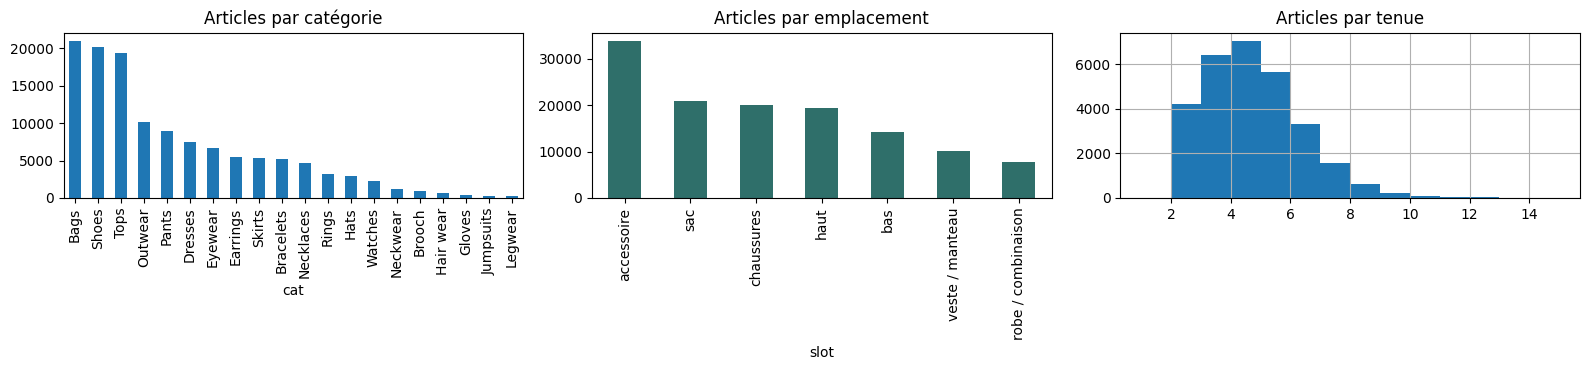

Tenues contenant une tenue de base complète : 41.8%


In [27]:
unk = items['cat'].isna().to_numpy()
if unk.any():
    P = encode_texts([f'a photo of {c.lower()}' for c in CATS20])
    items.loc[unk, 'cat'] = [CATS20[k] for k in (EMB[unk] @ P.T).argmax(1)]
print('Catégories attribuées en zéro-shot :', int(unk.sum()), f'({unk.mean():.1%})')

SLOT_OF = {'Tops': 'top', 'Skirts': 'bottom', 'Pants': 'bottom', 'Dresses': 'onepiece', 'Jumpsuits': 'onepiece',
           'Outwear': 'outer', 'Shoes': 'shoes', 'Bags': 'bag'}
SLOTS = ['top', 'bottom', 'onepiece', 'outer', 'shoes', 'bag', 'accessory']
SLOT_FR = {'top': 'haut', 'bottom': 'bas', 'onepiece': 'robe / combinaison', 'outer': 'veste / manteau',
           'shoes': 'chaussures', 'bag': 'sac', 'accessory': 'accessoire'}
items['slot'] = items['cat'].map(SLOT_OF).fillna('accessory')

ROW = {i: k for k, i in enumerate(items['item_id'].astype(str))}
raw['row'] = raw['item_id'].astype(str).map(ROW)
OUTFIT_ROWS = {o: sorted(set(g['row'])) for o, g in raw.groupby('outfit_id')}
OUTFIT_ROWS = {o: r for o, r in OUTFIT_ROWS.items() if len(r) >= 2}

split_of = raw.groupby('outfit_id')['split'].first().to_dict()
if np.mean([split_of.get(o) is None for o in OUTFIT_ROWS]) > 0.5:
    rg = np.random.RandomState(SEED)
    split_of = {o: ('train' if u < 0.8 else 'valid' if u < 0.9 else 'test') for o, u in zip(OUTFIT_ROWS, rg.rand(len(OUTFIT_ROWS)))}
    print('Pas de split dans les données -> tirage 80/10/10 par tenue')
SPLIT_OF = {o: split_of.get(o) or 'train' for o in OUTFIT_ROWS}

CAT_ARR = items['cat'].to_numpy(); SLOT_ARR = items['slot'].to_numpy()
SLOT_ID = np.array([SLOTS.index(s) for s in SLOT_ARR])
ROWS_OF = {s: sorted({r for o, rr in OUTFIT_ROWS.items() if SPLIT_OF[o] == s for r in rr}) for s in ['train', 'valid', 'test']}
print('Tenues par split :', Counter(SPLIT_OF.values()))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
items['cat'].value_counts().plot.bar(ax=ax[0], title='Articles par catégorie')
items['slot'].map(SLOT_FR).value_counts().plot.bar(ax=ax[1], title='Articles par emplacement', color='#2F6F6A')
pd.Series([len(r) for r in OUTFIT_ROWS.values()]).hist(bins=range(1, 16), ax=ax[2]); ax[2].set_title('Articles par tenue')
savefig('eda_categories_emplacements.png')

def has_core(rows):
    s = set(SLOT_ARR[rows]); return ({'top', 'bottom', 'shoes'} <= s) or ({'onepiece', 'shoes'} <= s)
print('Tenues contenant une tenue de base complète :', f"{np.mean([has_core(r) for r in OUTFIT_ROWS.values()]):.1%}")

## 5. Modèle de compatibilité entre deux pièces
**Question apprise :** « ces deux pièces vont-elles ensemble ? »
- **Positifs** : deux pièces d'emplacements différents présentes dans une même tenue réelle.
- **Négatifs difficiles** : on remplace l'une des deux pièces par une pièce **de la même catégorie** prise au hasard. Le modèle doit donc apprendre la compatibilité de style, pas « un haut va avec un bas ».
- **Modèle** : régression logistique sur `[zᵢ ⊙ zⱼ, |zᵢ − zⱼ|, type de paire]`, avec z = embedding réduit par ACP à 128 dimensions.
- **Référence** : la similarité cosinus FashionCLIP brute.
- **Seuil τ** : choisi sur la validation (indice de Youden) ; deux pièces sont dites compatibles si p ≥ τ.

Entraîné sur 200000 paires en 14s


,AUC paires (test),AUC tenues (test)
similarité cosinus (référence),0.619,0.791
modèle appris,0.649,0.820


Seuil τ = 0.506 | test : 56.9% des vraies paires et 35.3% des fausses paires sont jugées compatibles


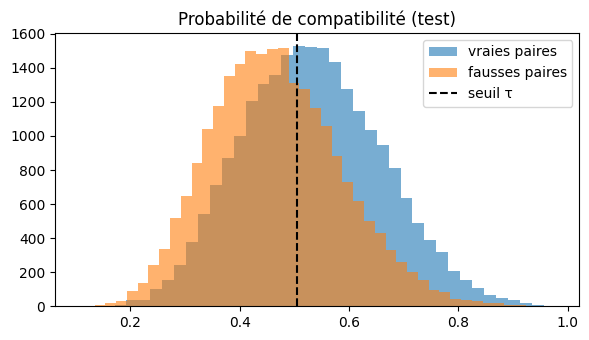

In [28]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

rg = np.random.RandomState(SEED)
tr = np.array(ROWS_OF['train'])
pca = PCA(min(PCA_DIM, EMB.shape[1]), random_state=SEED).fit(EMB[rg.choice(tr, min(50000, len(tr)), replace=False)])
Z = l2n(pca.transform(EMB))
NS = len(SLOTS); PAIR_ID = np.zeros((NS, NS), int); _k = 0
for a in range(NS):
    for b in range(a, NS): PAIR_ID[a, b] = PAIR_ID[b, a] = _k; _k += 1
N_PAIR_TYPES = _k

def pair_feats(i, j):
    i, j = np.asarray(i), np.asarray(j)
    oh = np.zeros((len(i), N_PAIR_TYPES), np.float32); oh[np.arange(len(i)), PAIR_ID[SLOT_ID[i], SLOT_ID[j]]] = 1
    return np.hstack([Z[i] * Z[j], np.abs(Z[i] - Z[j]), oh])

def make_pairs(split, max_pairs, seed):
    rg = np.random.RandomState(seed)
    by_cat = defaultdict(list)
    for r in ROWS_OF[split]: by_cat[CAT_ARR[r]].append(r)
    pos = [(a, b) for o, rr in OUTFIT_ROWS.items() if SPLIT_OF[o] == split
           for x, a in enumerate(rr) for b in rr[x + 1:] if SLOT_ARR[a] != SLOT_ARR[b] or SLOT_ARR[a] == 'accessory' and CAT_ARR[a] != CAT_ARR[b]]
    pos = np.array(pos); pos = pos[rg.permutation(len(pos))[: max_pairs // 2]]
    neg = pos.copy()
    for k in range(len(neg)):
        side = rg.randint(2); pool = by_cat[CAT_ARR[neg[k, side]]]
        neg[k, side] = pool[rg.randint(len(pool))]
    I = np.r_[pos[:, 0], neg[:, 0]]; J = np.r_[pos[:, 1], neg[:, 1]]; y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
    return I, J, y

t0 = time.time()
I_tr, J_tr, y_tr = make_pairs('train', MAX_TRAIN_PAIRS, 1)
COMPAT = LogisticRegression(C=1.0, max_iter=1000).fit(pair_feats(I_tr, J_tr), y_tr)
print(f'Entraîné sur {len(y_tr)} paires en {time.time() - t0:.0f}s')

def p_compat(i, j): return COMPAT.predict_proba(pair_feats(i, j))[:, 1]
def cos(i, j): return (Z[np.asarray(i)] * Z[np.asarray(j)]).sum(1)

I_va, J_va, y_va = make_pairs('valid', 60000, 2)
I_te, J_te, y_te = make_pairs('test', 60000, 3)
fpr, tpr, thr = roc_curve(y_va, p_compat(I_va, J_va))
TAU = float(thr[np.argmax(tpr - fpr)])
p_te = p_compat(I_te, J_te)

# Tâche « compatibilité de tenue » : vraie tenue vs tenue dont chaque pièce est remplacée par une pièce de même catégorie
by_cat_te = defaultdict(list)
for r in ROWS_OF['test']: by_cat_te[CAT_ARR[r]].append(r)
def outfit_score(rows, f):
    rows = np.array(rows); a, b = np.triu_indices(len(rows), 1)
    return float(f(rows[a], rows[b]).mean()) if len(a) else 0.0
rg = np.random.RandomState(4); real, fake = [], []
for o, rr in OUTFIT_ROWS.items():
    if SPLIT_OF[o] != 'test' or len(rr) < 3: continue
    real.append(rr); fake.append([by_cat_te[CAT_ARR[r]][rg.randint(len(by_cat_te[CAT_ARR[r]]))] for r in rr])
real, fake = real[:2000], fake[:2000]
yo = np.r_[np.ones(len(real)), np.zeros(len(fake))]
COMPAT_DF = pd.DataFrame({
    'AUC paires (test)': [roc_auc_score(y_te, cos(I_te, J_te)), roc_auc_score(y_te, p_te)],
    'AUC tenues (test)': [roc_auc_score(yo, [outfit_score(r, cos) for r in real + fake]),
                          roc_auc_score(yo, [outfit_score(r, p_compat) for r in real + fake])]},
    index=['similarité cosinus (référence)', 'modèle appris']).round(3)
display(COMPAT_DF); COMPAT_DF.to_csv(WORK / 'compatibilite.csv')
print(f'Seuil τ = {TAU:.3f} | test : {np.mean(p_te[y_te == 1] >= TAU):.1%} des vraies paires et '
      f'{np.mean(p_te[y_te == 0] >= TAU):.1%} des fausses paires sont jugées compatibles')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(p_te[y_te == 1], bins=40, alpha=.6, label='vraies paires'); ax.hist(p_te[y_te == 0], bins=40, alpha=.6, label='fausses paires')
ax.axvline(TAU, color='k', ls='--', label='seuil τ'); ax.set_title('Probabilité de compatibilité (test)'); ax.legend()
savefig('compatibilite_distribution.png')

## 5.b Entraînement, sélection et évaluation du modèle de compatibilité

Jusqu'ici le « modèle » était **une régression logistique à réglages fixes** (C = 1, 13 s, aucune courbe). Un évaluateur attend un vrai protocole :
1. **Sélection d'hyperparamètres sur la validation** (le test n'est touché qu'à la fin) ;
2. **courbe d'apprentissage** (le modèle manque-t-il de données ou de capacité ?) ;
3. un **challenger non linéaire** (réseau MLP, avec arrêt anticipé et courbe de perte) ;
4. **trois métriques** : AUC sur paires, AUC sur tenues, et **FITB** (*fill-in-the-blank*, la métrique standard sur Polyvore : retrouver la pièce manquante parmi 4 candidats de la même catégorie, hasard = 25 %) ;
5. un **contrôle de fuite** (quasi-doublons entre apprentissage et test).


,modèle,réglage,AUC_valid
0,régression logistique,C=0.01,0.6278
1,régression logistique,C=0.1,0.6368
2,régression logistique,C=1.0,0.6445
3,régression logistique,C=10.0,0.6463
4,MLP (challenger),"couches=(128,)",0.6509
5,MLP (challenger),"couches=(256, 64)",0.6448


Choix (validation) : régression logistique C=10.0 | MLP couches=(128,)


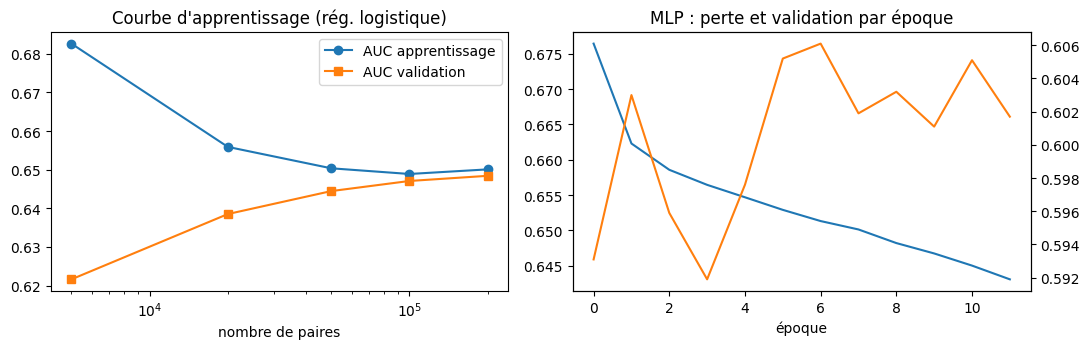

,AUC paires,AUC tenues,"FITB (hasard = 0,25)"
similarité cosinus (référence),0.619,0.791,0.549 ± 0.022
régression logistique réglée (C=10.0),0.652,0.827,0.554 ± 0.022
"MLP (128,) (challenger)",0.656,0.834,0.548 ± 0.022


Seuil τ = 0.515 | vraies paires jugées compatibles : 54.4% | FAUSSES paires jugées compatibles : 32.5% (c'est ce taux de faux positifs qui rend tout « compatible »)


,type de paire,n,AUC test
8,bas × accessoire,3030,0.605
19,accessoire × accessoire,3892,0.628
7,bas × sac,1878,0.628
15,veste / manteau × accessoire,2264,0.636
9,robe / combinaison × veste / manteau,442,0.638
0,haut × bas,2496,0.639
4,haut × accessoire,4270,0.642
1,haut × veste / manteau,1316,0.645
18,sac × accessoire,4762,0.646
2,haut × chaussures,2534,0.650


Fuite possible : 14.6% des articles de test ont un quasi-doublon (cosinus > 0,95) dans un échantillon de l'apprentissage | médiane du meilleur cosinus : 0.849
Section 5.b terminée en 188s


In [29]:
from sklearn.neural_network import MLPClassifier

NAMES_PT = {PAIR_ID[a, b]: f'{SLOT_FR[SLOTS[a]]} × {SLOT_FR[SLOTS[b]]}' for a in range(NS) for b in range(a, NS)}
t0 = time.time(); Xva = pair_feats(I_va, J_va)
sub = np.random.RandomState(0).permutation(len(y_tr))[:100_000]; Xs, ys = pair_feats(I_tr[sub], J_tr[sub]), y_tr[sub]

# ---- 1. Sélection d'hyperparamètres (validation) ----
SEL = []; LRS = {}
for C_ in (0.01, 0.1, 1.0, 10.0):
    m_ = LogisticRegression(C=C_, max_iter=1000).fit(Xs, ys); LRS[C_] = m_
    SEL.append(dict(modèle='régression logistique', réglage=f'C={C_}', AUC_valid=roc_auc_score(y_va, m_.predict_proba(Xva)[:, 1])))
MLPS = {}
for hl in [(128,), (256, 64)]:
    m_ = MLPClassifier(hl, alpha=1e-4, early_stopping=True, n_iter_no_change=4, max_iter=40, random_state=SEED).fit(Xs, ys); MLPS[hl] = m_
    SEL.append(dict(modèle='MLP (challenger)', réglage=f'couches={hl}', AUC_valid=roc_auc_score(y_va, m_.predict_proba(Xva)[:, 1])))
SEL_DF = pd.DataFrame(SEL).round(4); display(SEL_DF); SEL_DF.to_csv(WORK / 'selection_hyperparametres.csv', index=False)
best_C = max(LRS, key=lambda c: SEL_DF[(SEL_DF.réglage == f'C={c}')].AUC_valid.iloc[0])
best_hl = max(MLPS, key=lambda h: SEL_DF[(SEL_DF.réglage == f'couches={h}')].AUC_valid.iloc[0]); MLP = MLPS[best_hl]
print(f'Choix (validation) : régression logistique C={best_C} | MLP couches={best_hl}')

# ---- 2. Modèle final : régression logistique réglée, ré-entraînée sur toutes les paires ----
COMPAT = LogisticRegression(C=best_C, max_iter=1000).fit(pair_feats(I_tr, J_tr), y_tr)
fpr, tpr, thr = roc_curve(y_va, p_compat(I_va, J_va)); TAU = float(thr[np.argmax(tpr - fpr)]); p_te = p_compat(I_te, J_te)
def p_mlp(i, j): return MLP.predict_proba(pair_feats(i, j))[:, 1]

# ---- 3. Courbes : apprentissage (régression logistique) et perte (MLP) ----
sizes = [s for s in (5_000, 20_000, 50_000, 100_000, len(y_tr)) if s <= len(y_tr)]; lc = []
for n_ in sizes:
    idx_ = np.random.RandomState(1).permutation(len(y_tr))[:n_]; m_ = LogisticRegression(C=best_C, max_iter=1000).fit(pair_feats(I_tr[idx_], J_tr[idx_]), y_tr[idx_])
    lc.append((n_, roc_auc_score(y_tr[idx_][:20000], m_.predict_proba(pair_feats(I_tr[idx_][:20000], J_tr[idx_][:20000]))[:, 1]), roc_auc_score(y_va, m_.predict_proba(Xva)[:, 1])))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); lc = np.array(lc)
ax[0].plot(lc[:, 0], lc[:, 1], 'o-', label='AUC apprentissage'); ax[0].plot(lc[:, 0], lc[:, 2], 's-', label='AUC validation'); ax[0].set_xscale('log'); ax[0].legend()
ax[0].set_title('Courbe d\'apprentissage (rég. logistique)'); ax[0].set_xlabel('nombre de paires')
ax[1].plot(MLP.loss_curve_, label='perte (apprentissage)'); ax2 = ax[1].twinx(); ax2.plot(MLP.validation_scores_, color='C1', label='précision de validation interne'); ax[1].set_title('MLP : perte et validation par époque'); ax[1].set_xlabel('époque')
savefig('entrainement_courbes.png')

# ---- 4. FITB : 4 candidats de la même catégorie, hasard = 25 % ----
def fitb_set(split, n, seed, k=4):
    rg_ = np.random.RandomState(seed); pool = defaultdict(list)
    for r in ROWS_OF[split]: pool[CAT_ARR[r]].append(r)
    oids = [o for o, rr in OUTFIT_ROWS.items() if SPLIT_OF[o] == split and len(rr) >= 3]; out = []
    for o in rg_.permutation(len(oids))[:n]:
        rr = OUTFIT_ROWS[oids[o]]; h = rr[rg_.randint(len(rr))]; rest = [r for r in rr if r != h]; cands = [h]; tries = 0
        while len(cands) < k and tries < 200:
            c = pool[CAT_ARR[h]][rg_.randint(len(pool[CAT_ARR[h]]))]; tries += 1
            if c not in rr and c not in cands: cands.append(c)
        if len(cands) == k: out.append((rest, cands))
    return out
def fitb_acc(f, data):
    wins = []
    for rest, cands in data:
        ii = np.repeat(cands, len(rest)); jj = np.tile(rest, len(cands)); s = np.asarray(f(ii, jj)).reshape(len(cands), len(rest)).mean(1)
        wins.append(bool((s[1:] < s[0]).all()))         # égalité = échec (pas de biais en faveur de la vraie pièce)
    a = float(np.mean(wins)); return a, 1.96 * math.sqrt(a * (1 - a) / len(wins))
FITB_TE = fitb_set('test', 300 if SMOKE_TEST else 2000, 6)

# ---- 5. Évaluation finale sur le TEST ----
def row_for(name, f):
    a, ci = fitb_acc(f, FITB_TE)
    return {'AUC paires': roc_auc_score(y_te, f(I_te, J_te)), 'AUC tenues': roc_auc_score(yo, [outfit_score(r, f) for r in real + fake]), 'FITB (hasard = 0,25)': f'{a:.3f} ± {ci:.3f}'}
FINAL_DF = pd.DataFrame({'similarité cosinus (référence)': row_for('cos', cos), f'régression logistique réglée (C={best_C})': row_for('lr', p_compat),
                         f'MLP {best_hl} (challenger)': row_for('mlp', p_mlp)}).T
FINAL_DF[['AUC paires', 'AUC tenues']] = FINAL_DF[['AUC paires', 'AUC tenues']].astype(float).round(3); display(FINAL_DF); FINAL_DF.to_csv(WORK / 'evaluation_modele_compatibilite.csv')
print(f'Seuil τ = {TAU:.3f} | vraies paires jugées compatibles : {np.mean(p_te[y_te == 1] >= TAU):.1%} | FAUSSES paires jugées compatibles : {np.mean(p_te[y_te == 0] >= TAU):.1%}'
      f' (c\'est ce taux de faux positifs qui rend tout « compatible »)')
pid_te = PAIR_ID[SLOT_ID[I_te], SLOT_ID[J_te]]
PT_DF = pd.DataFrame([(NAMES_PT[k], int((pid_te == k).sum()), roc_auc_score(y_te[pid_te == k], p_te[pid_te == k])) for k in np.unique(pid_te)
                      if (pid_te == k).sum() >= 300 and 0 < y_te[pid_te == k].mean() < 1], columns=['type de paire', 'n', 'AUC test']).sort_values('AUC test').round(3)
display(PT_DF); PT_DF.to_csv(WORK / 'auc_par_type_de_paire.csv', index=False)

# ---- 6. Contrôle de fuite : un article de test a-t-il un quasi-doublon dans l'apprentissage ? ----
EMBn = l2n(EMB); rs_ = np.random.RandomState(3)
te_s = rs_.choice(ROWS_OF['test'], min(1500, len(ROWS_OF['test'])), replace=False); tr_s = rs_.choice(ROWS_OF['train'], min(30000, len(ROWS_OF['train'])), replace=False)
mx = np.concatenate([(EMBn[te_s[k:k + 500]] @ EMBn[tr_s].T).max(1) for k in range(0, len(te_s), 500)])
print(f'Fuite possible : {np.mean(mx > 0.95):.1%} des articles de test ont un quasi-doublon (cosinus > 0,95) dans un échantillon de l\'apprentissage | médiane du meilleur cosinus : {np.median(mx):.3f}')
print(f'Section 5.b terminée en {time.time() - t0:.0f}s')


## 6. Compter les combinaisons d'une garde-robe
**Définition retenue (documentée, modifiable dans `CORE` et `LAYERS`) :**
- une **tenue de base** = *haut + bas + chaussures* ou *robe/combinaison + chaussures*, dont **toutes les paires** sont compatibles ;
- chaque tenue de base peut être portée **avec ou sans** une veste compatible, et **avec ou sans** un sac compatible (compatible avec toutes les pièces de la tenue) ;
- nombre de **combinaisons** = Σ sur les tenues de base de (1 + nb vestes compatibles) × (1 + nb sacs compatibles).

Les accessoires (bijoux, chapeaux…) ne sont pas comptés, pour éviter que leur nombre fasse exploser le total.

In [30]:
CORE = [('top', 'bottom', 'shoes'), ('onepiece', 'shoes')]
LAYERS = ['outer', 'bag']
LAYER_MODE = 'mult'   # 'mult' : chaque veste/sac compatible multiplie les tenues (original) | 'cap' : une veste et un sac ajoutent au plus ×2 chacun

def count_combos(slots, B):
    # slots : emplacement de chaque pièce ; B : matrice booléenne de compatibilité (n x n)
    idx = {s: np.where(slots == s)[0] for s in SLOTS}
    base = total = 0
    for pat in CORE:
        ids = [idx[s] for s in pat]
        if any(len(x) == 0 for x in ids): continue
        k = len(pat); V = np.ones([len(x) for x in ids], bool)
        for a in range(k):
            for b in range(a + 1, k):
                sh = [1] * k; sh[a] = len(ids[a]); sh[b] = len(ids[b])
                V = V & B[np.ix_(ids[a], ids[b])].reshape(sh)
        mult = np.ones(V.shape)
        for L in LAYERS:
            l = idx[L]
            if len(l) == 0: continue
            ok = np.ones((len(l),) + V.shape, bool)
            for a in range(k):
                sh = [len(l)] + [1] * k; sh[a + 1] = len(ids[a])
                ok = ok & B[np.ix_(l, ids[a])].reshape(sh)
            mult = mult * (1 + (ok.sum(0) if LAYER_MODE == 'mult' else np.minimum(ok.sum(0), 1)))
        base += int(V.sum()); total += int((V * mult).sum())
    return base, total

def compat_matrix(rows):
    rows = np.asarray(rows); n = len(rows); P = np.zeros((n, n), np.float32)
    a, b = np.triu_indices(n, 1)
    if len(a): P[a, b] = P[b, a] = p_compat(rows[a], rows[b])
    return P

# Contrôle : une vraie tenue de test est-elle reconnue comme combinaison valide ?
chk = [r for r in real if has_core(r)][:1000]
rec = np.mean([count_combos(SLOT_ARR[np.array(r)], compat_matrix(r) >= TAU)[0] > 0 for r in chk])
rec_f = np.mean([count_combos(SLOT_ARR[np.array(r)], compat_matrix(r) >= TAU)[0] > 0
                 for r in [fake[real.index(x)] for x in chk]])
print(f'Vraies tenues reconnues comme valides : {rec:.1%} | tenues mélangées au hasard : {rec_f:.1%}')

Vraies tenues reconnues comme valides : 34.7% | tenues mélangées au hasard : 13.0%


## 7. Détection des pièces manquantes
Pour une garde-robe **W** et un ensemble d'articles candidats **C** (le « magasin ») :
- **gain(c)** = combinaisons(W ∪ {c}) − combinaisons(W) : le nombre de **nouvelles tenues** que l'article crée ;
- **rapport par emplacement** : combien de pièces on possède par emplacement et le meilleur gain possible dans chacun → montre où est le vrai manque (ex. « aucune chaussure : 0 tenue possible ») ;
- **panier glouton** : on achète la pièce au plus fort gain, on recalcule, on recommence K fois (chaque achat tient compte des précédents).

Le score de classement est le gain, départagé par la compatibilité moyenne avec la garde-robe. Si le prix est connu, on affiche aussi le gain par dollar.

In [31]:
class GapScene:
    # Garde-robe + candidats, avec la matrice de compatibilité calculée une seule fois
    def __init__(self, W, C):
        self.W, self.C = np.asarray(W), np.asarray(C)
        self.rows = np.r_[self.W, self.C]; self.nW = len(self.W)
        self.P = compat_matrix(self.rows); self.B = self.P >= TAU; self.slots = SLOT_ARR[self.rows]
    def combos(self, local):
        local = np.asarray(local, int); return count_combos(self.slots[local], self.B[np.ix_(local, local)])
    def gains(self, owned=None):
        owned = np.arange(self.nW) if owned is None else np.asarray(owned, int)
        _, t0 = self.combos(owned)
        cand = [k for k in range(self.nW, len(self.rows)) if k not in set(owned)]
        g = np.array([self.combos(np.r_[owned, k])[1] - t0 for k in cand])
        cand = np.array(cand, int)
        diff = self.slots[cand][:, None] != self.slots[owned][None, :]
        mp = (self.P[np.ix_(cand, owned)] * diff).sum(1) / np.maximum(diff.sum(1), 1)
        return cand, g, mp
    def rank(self):
        cand, g, mp = self.gains(); score = g + 1e-3 * mp
        o = np.argsort(-score); return cand[o], g[o], score[o]
    def greedy(self, K):
        owned = list(range(self.nW)); hist = [self.combos(owned)[1]]; picks = []
        for _ in range(K):
            cand, g, mp = self.gains(owned)
            if len(cand) == 0: break
            k = int(np.argmax(g + 1e-3 * mp)); owned.append(int(cand[k])); picks.append(int(cand[k]))
            hist.append(self.combos(owned)[1])
        return picks, hist
    def slot_report(self):
        cand, g, _ = self.gains(); rows = []
        for s in SLOTS:
            m = self.slots[cand] == s
            best = int(np.argmax(np.where(m, g, -1))) if m.any() else None
            rows.append(dict(emplacement=SLOT_FR[s], possédées=int((self.slots[:self.nW] == s).sum()),
                             meilleur_gain=int(g[best]) if best is not None else 0,
                             gain_moyen=float(g[m].mean()) if m.any() else 0.0))
        return pd.DataFrame(rows).sort_values('meilleur_gain', ascending=False)

## 7.b Promiscuité (« compatible avec tout ») et correction

**Le problème.** Une pièce noire, sobre, « centrale » dans l'espace des embeddings est jugée compatible avec presque tout. Le gain en combinaisons la récompense, donc la méthode recommande des **pièces universelles** (jeans noir, baskets noires, sac) plutôt que des pièces qui complètent *vraiment* une garde-robe. En apprentissage automatique on appelle cela la **hubness** (des « hubs » attirent tous les voisins).

**Deux corrections.**
1. **Centrer par pièce** (idée de CSLS) : on retire à chaque score la compatibilité *moyenne* de chaque pièce avec un échantillon d'articles de l'autre emplacement. Un score élevé signifie alors « va avec **ça** » et non « va avec **tout** ».
2. **Un seuil par type de paire** (haut×bas, bas×chaussures, etc.) au lieu d'un seuil global unique.

**Un défaut de comptage.** Les vestes et sacs *multipliaient* les tenues : un seul sac compatible doublait le total, d'où « sac » en tête et acheté deux fois. En mode `cap`, chaque couche ajoute au plus ×2.

On garde les **deux versions** (brute / corrigée) pour pouvoir les comparer honnêtement en 8.b.


Seuils par type de paire calibrés en 8s


,brut,corrigé
mean,0.317,0.326
std,0.063,0.053
50%,0.314,0.323
max,0.520,0.485


Pièces compatibles avec plus de 70 % des autres : brut 0.0% | corrigé 0.0%


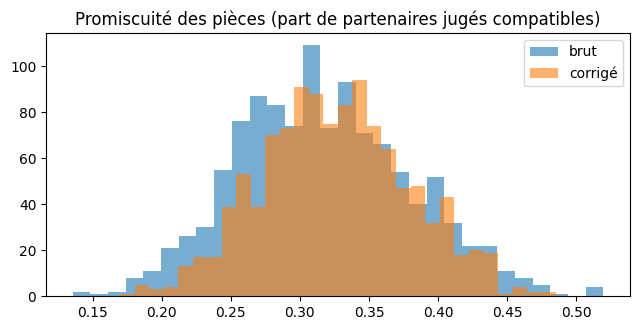

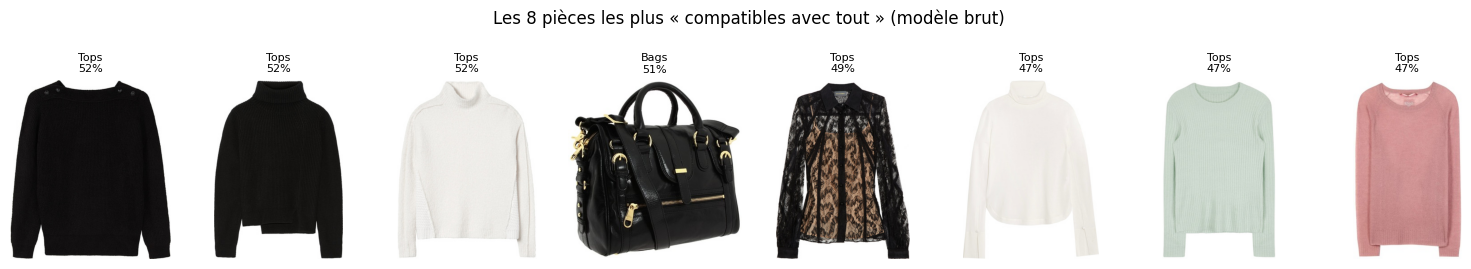

In [32]:
compat_matrix_raw = compat_matrix      # fonction d'origine (cellule 6)
TAU_RAW, TAU_HUB, USE_HUB = TAU, 0.5, False
def _logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

# échantillon de référence : quelques articles d'entraînement par emplacement
rg_h = np.random.RandomState(99); trs = np.array(ROWS_OF['train']); REF_N = 15 if SMOKE_TEST else 30; REF_ROWS, REF_SLOT = [], []
for s_ in SLOTS:
    pool_ = trs[SLOT_ARR[trs] == s_]
    if len(pool_): pk = rg_h.choice(pool_, min(REF_N, len(pool_)), replace=False); REF_ROWS += pk.tolist(); REF_SLOT += [SLOTS.index(s_)] * len(pk)
REF_ROWS, REF_SLOT = np.array(REF_ROWS), np.array(REF_SLOT); _RH = {}

def hub_offsets(rows):
    # pour chaque pièce : logit moyen de compatibilité avec un article « typique » de chaque emplacement (mis en cache)
    rows = np.asarray(rows, int); need = np.array([r for r in dict.fromkeys(rows.tolist()) if r not in _RH], int)
    for ch in (np.array_split(need, max(1, len(need) // 1500 + 1)) if len(need) else []):
        ii = np.repeat(ch, len(REF_ROWS)); jj = np.tile(REF_ROWS, len(ch)); lg = _logit(p_compat(ii, jj)).reshape(len(ch), len(REF_ROWS))
        off = np.stack([lg[:, REF_SLOT == k].mean(1) if (REF_SLOT == k).any() else np.zeros(len(ch)) for k in range(NS)], 1)
        for r, o in zip(ch, off): _RH[int(r)] = o
    return np.stack([_RH[int(r)] for r in rows])

def hub_logit(i, j):
    i, j = np.asarray(i, int), np.asarray(j, int); Ri, Rj = hub_offsets(i), hub_offsets(j)
    return _logit(p_compat(i, j)) - 0.5 * (Ri[np.arange(len(i)), SLOT_ID[j]] + Rj[np.arange(len(j)), SLOT_ID[i]])

def fit_pair_bias(I, J, y, min_n=200):
    L = hub_logit(I, J); pid = PAIR_ID[SLOT_ID[I], SLOT_ID[J]]
    fp, tp, th = roc_curve(y, L); b = np.full(N_PAIR_TYPES, float(th[np.argmax(tp - fp)]))
    for k in range(N_PAIR_TYPES):
        m = pid == k
        if m.sum() >= min_n and 0 < y[m].mean() < 1: fp, tp, th = roc_curve(y[m], L[m]); b[k] = float(th[np.argmax(tp - fp)])
    return b
t0 = time.time(); B_PAIR = fit_pair_bias(I_va, J_va, y_va); print(f'Seuils par type de paire calibrés en {time.time() - t0:.0f}s')

def compat_matrix_hub(rows):
    rows = np.asarray(rows); n = len(rows); P = np.zeros((n, n), np.float32); a, b = np.triu_indices(n, 1)
    if len(a):
        L = hub_logit(rows[a], rows[b]) - B_PAIR[PAIR_ID[SLOT_ID[rows[a]], SLOT_ID[rows[b]]]]; P[a, b] = P[b, a] = 1 / (1 + np.exp(-L))
    return P
def compat_matrix(rows): return compat_matrix_hub(rows) if USE_HUB else compat_matrix_raw(rows)
def set_variant(hub, layers):
    global USE_HUB, LAYER_MODE, TAU
    USE_HUB, LAYER_MODE = bool(hub), layers; TAU = TAU_HUB if hub else TAU_RAW

# ---- Diagnostic : à quel point les pièces sont-elles « compatibles avec tout » ? ----
rs_ = np.random.RandomState(5); te_all = np.array(ROWS_OF['test']); meas = rs_.choice(te_all, min(1500, len(te_all)), replace=False); PART = rs_.choice(te_all, min(150, len(te_all)), replace=False)
PROM_C = {False: {}, True: {}}
def promisc(rows, hub):
    # part des articles d'un AUTRE emplacement (parmi 150 articles de test) avec lesquels la pièce est jugée compatible
    cache = PROM_C[hub]; rows = np.asarray(rows, int); need = np.array([r for r in dict.fromkeys(rows.tolist()) if r not in cache], int)
    if len(need):
        ii = np.repeat(need, len(PART)); jj = np.tile(PART, len(need)); diff = (SLOT_ID[ii] != SLOT_ID[jj])
        ok_ = ((1 / (1 + np.exp(-(hub_logit(ii, jj) - B_PAIR[PAIR_ID[SLOT_ID[ii], SLOT_ID[jj]]])))) >= TAU_HUB) if hub else (p_compat(ii, jj) >= TAU_RAW)
        num = (ok_ & diff).reshape(len(need), -1).sum(1); den = diff.reshape(len(need), -1).sum(1)
        for r, v in zip(need, num / np.maximum(den, 1)): cache[int(r)] = float(v)
    return np.array([cache[int(r)] for r in rows])
cnt_ = SLOT_ARR[meas] != 'accessory'; meas = meas[cnt_]
pr_raw, pr_hub = promisc(meas, False), promisc(meas, True)
PROM_DF = pd.DataFrame({'brut': pd.Series(pr_raw).describe(), 'corrigé': pd.Series(pr_hub).describe()}).round(3).loc[['mean', 'std', '50%', 'max']]; display(PROM_DF)
print(f'Pièces compatibles avec plus de 70 % des autres : brut {np.mean(pr_raw > .7):.1%} | corrigé {np.mean(pr_hub > .7):.1%}')
fig, ax = plt.subplots(figsize=(6.5, 3.4)); ax.hist(pr_raw, bins=30, alpha=.6, label='brut'); ax.hist(pr_hub, bins=30, alpha=.6, label='corrigé'); ax.set_title('Promiscuité des pièces (part de partenaires jugés compatibles)'); ax.legend(); savefig('promiscuite_avant_apres.png')
from PIL import Image as PILImage
order_ = np.argsort(-pr_raw)[:8]; top_ = meas[order_]
fig, axs = plt.subplots(1, len(top_), figsize=(1.9 * len(top_), 2.7)); axs = np.atleast_1d(axs)
for a_, r_, v_ in zip(axs, top_, pr_raw[order_]):
    try: a_.imshow(PILImage.open(items['path'][r_]).convert('RGB'))
    except Exception: a_.text(.5, .5, CAT_ARR[r_], ha='center')
    a_.set_title(f'{CAT_ARR[r_]}\n{v_:.0%}', fontsize=8); a_.axis('off')
fig.suptitle('Les 8 pièces les plus « compatibles avec tout » (modèle brut)'); savefig('pieces_les_plus_promiscues.png')


## 8. Évaluation
**Garde-robes simulées** : une tenue de test « graine » + ses 3 tenues de test les plus proches en style (une vraie personne a un goût cohérent).

**Test 1 — retrouver la pièce manquante (indépendant du compteur) :** on retire de la garde-robe une pièce de base (haut, bas, robe ou chaussures) de la tenue graine. On la mélange à 99 articles de test pris au hasard, toutes catégories confondues. Le système doit la classer haut : **Hit@10** (hasard ≈ 10 %) et **MRR**.

Comparaisons :
- hasard ;
- **similarité** : ressemblance moyenne avec la garde-robe ;
- **emplacement le plus rare** : règle « achète ce qui manque le plus » ;
- **compatibilité moyenne** : sans compter les combinaisons ;
- **gain en combinaisons** : notre méthode.

**Test 2 — combinaisons après K achats :** panier glouton vs top-K par similarité, emplacement le plus rare et hasard. Attention : ce test utilise le même modèle de compatibilité que la méthode ; il mesure l'optimisation, alors que le test 1 mesure la pertinence.

400 garde-robes évaluées en 20s


,Hit@10,MRR
hasard,0.092,0.046
similarité,0.670,0.355
emplacement le plus rare,0.188,0.111
compatibilité moyenne,0.595,0.314
gain en combinaisons (notre méthode),0.682,0.338


Hasard attendu : Hit@10 = 0.10 | la pièce cachée crée au moins une tenue dans 86.2% des cas


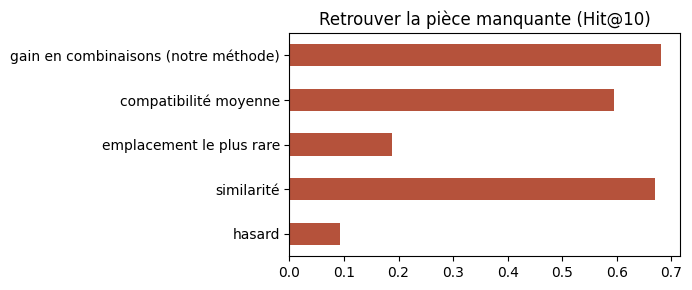

In [33]:
te_oids = [o for o, r in OUTFIT_ROWS.items() if SPLIT_OF[o] == 'test' and has_core(r)]
OV = l2n(np.stack([Z[OUTFIT_ROWS[o]].mean(0) for o in te_oids]))
te_items = np.array(ROWS_OF['test'])
CORE_SLOTS = {'top', 'bottom', 'onepiece', 'shoes'}

def make_wardrobes(n, seed):
    rg = np.random.RandomState(seed); out = []
    for s in rg.permutation(len(te_oids))[:n]:
        nn = np.argsort(-(OV @ OV[s]))[:OUTFITS_PER_WARDROBE]
        oids = [te_oids[s]] + [te_oids[k] for k in nn if k != s][:OUTFITS_PER_WARDROBE - 1]
        W = sorted({r for o in oids for r in OUTFIT_ROWS[o]})
        core = [r for r in OUTFIT_ROWS[te_oids[s]] if SLOT_ARR[r] in CORE_SLOTS]
        h = core[rg.randint(len(core))]
        excl = set(W)
        pool = np.array([r for r in rg.choice(te_items, min(len(te_items), 3 * N_CANDIDATES), replace=False) if r not in excl])
        out.append(dict(W=[r for r in W if r != h], h=h, C=np.r_[h, pool[:N_CANDIDATES - 1]], oids=oids))
    return out

WARDS = make_wardrobes(N_WARDROBES, 7)
rg = np.random.RandomState(11); res = defaultdict(list); t0 = time.time()
for w in WARDS:
    sc = GapScene(w['W'], w['C']); cand, g, mp = sc.gains()
    rows_c = sc.rows[cand]; W = np.array(w['W'])
    simv = (Z[rows_c] @ Z[W].T).mean(1)
    cnt = Counter(SLOT_ARR[W])
    rare = np.array([-cnt.get(SLOT_ARR[r], 0) if SLOT_ARR[r] in CORE_SLOTS | {'outer', 'bag'} else -99 for r in rows_c], float)
    scores = {'hasard': rg.rand(len(cand)), 'similarité': simv, 'emplacement le plus rare': rare + 1e-3 * simv,
              'compatibilité moyenne': mp, 'gain en combinaisons (notre méthode)': g + 1e-3 * mp}
    tgt = int(np.where(rows_c == w['h'])[0][0])
    for m, s in scores.items():
        rank = 1 + int((s > s[tgt]).sum())
        res[m].append((rank <= 10, 1 / rank))
    res['_gain_cible'].append(g[tgt])
print(f'{len(WARDS)} garde-robes évaluées en {time.time() - t0:.0f}s')
EVAL_DF = pd.DataFrame({m: {'Hit@10': np.mean([a for a, _ in v]), 'MRR': np.mean([b for _, b in v])}
                        for m, v in res.items() if not m.startswith('_')}).T.round(3)
display(EVAL_DF); EVAL_DF.to_csv(WORK / 'evaluation_piece_manquante.csv')
print(f'Hasard attendu : Hit@10 = {10 / N_CANDIDATES:.2f} | la pièce cachée crée au moins une tenue dans '
      f"{np.mean(np.array(res['_gain_cible']) > 0):.1%} des cas")
EVAL_DF['Hit@10'].plot.barh(figsize=(7, 3), title='Retrouver la pièce manquante (Hit@10)', color='#B5523B')
savefig('evaluation_hit10.png')

,panier glouton (notre méthode),similarité,emplacement le plus rare,hasard
achats,,,,
0,32.6,32.6,32.6,32.6
1,54.3,42.5,40.0,33.5
2,76.5,51.2,44.6,34.4
3,100.3,60.5,48.9,36.2
4,125.7,70.4,52.2,37.5
5,152.6,82.9,55.5,39.0


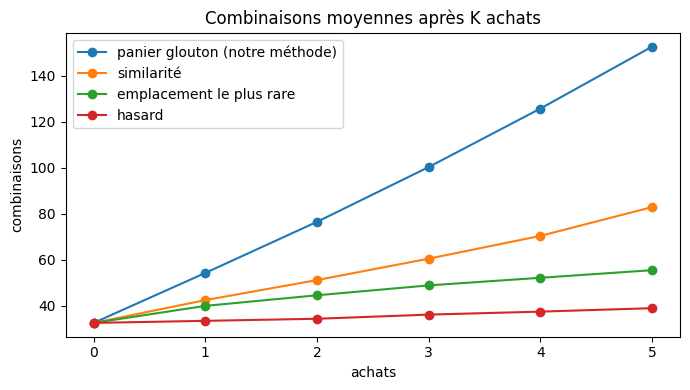

In [34]:
curves = defaultdict(list); rg = np.random.RandomState(12)
for w in WARDS[:N_CURVE]:
    sc = GapScene(w['W'], w['C']); nW = sc.nW; cand = np.arange(nW, len(sc.rows))
    W = np.array(w['W']); rows_c = sc.rows[cand]
    simv = (Z[rows_c] @ Z[W].T).mean(1); cnt = Counter(SLOT_ARR[W])
    rare = np.array([-cnt.get(SLOT_ARR[r], 0) if SLOT_ARR[r] in CORE_SLOTS | {'outer', 'bag'} else -99 for r in rows_c], float)
    _, hist = sc.greedy(K_BUY); curves['panier glouton (notre méthode)'].append(hist + [hist[-1]] * (K_BUY + 1 - len(hist)))
    for m, s in {'similarité': simv, 'emplacement le plus rare': rare + 1e-3 * simv, 'hasard': rg.rand(len(cand))}.items():
        order = cand[np.argsort(-s)]
        curves[m].append([sc.combos(np.r_[np.arange(nW), order[:k]])[1] for k in range(K_BUY + 1)])
CURVE_DF = pd.DataFrame({m: np.mean(v, 0) for m, v in curves.items()}, index=pd.Index(range(K_BUY + 1), name='achats')).round(1)
display(CURVE_DF); CURVE_DF.to_csv(WORK / 'combinaisons_vs_achats.csv')
ax = CURVE_DF.plot(marker='o', figsize=(7, 4), title='Combinaisons moyennes après K achats')
ax.set_ylabel('combinaisons'); savefig('combinaisons_vs_achats.png')

## 8.b Évaluation plus exigeante : le gain bat-il vraiment la similarité ?

L'évaluation de la section 8 a quatre faiblesses qu'un jury relèverait :
- **Biais de construction** : la garde-robe est fabriquée avec les 4 tenues *les plus proches en style* ; la **similarité** est donc avantagée d'avance.
- **Candidats hétérogènes** : 99 articles tirés au hasard (toutes catégories) rendent le test trop facile.
- **Pas d'intervalle de confiance** : 0,672 contre 0,670 est-il une différence ?
- **Pièce cachée toujours « de base »** (haut, bas, chaussures) alors que la méthode recommande surtout sacs et vestes.

On ajoute donc : un **scénario mixte** (garde-robe non cohérente) avec **candidats du même emplacement**, des **IC à 95 %** (bootstrap), un test de **victoire par paires** (la vraie pièce bat-elle un article du même emplacement ? hasard = 0,5) et la **corrélation gain ↔ promiscuité** (si elle est forte, le gain ne mesure que « va avec tout »). Trois variantes sont comparées : **A** brut + couches multiplicatives (original), **B** brut + couches plafonnées, **C** corrigé + plafonnées.


In [35]:
from scipy.stats import spearmanr
N_EVAL = 30 if SMOKE_TEST else 200
SL_ITEMS = {s_: te_items[SLOT_ARR[te_items] == s_] for s_ in SLOTS}

def make_wardrobes2(n, seed, mixed=True, same_slot=True):
    rg_ = np.random.RandomState(seed); out = []
    for s in rg_.permutation(len(te_oids))[:n]:
        if mixed: oids = [te_oids[s]] + [te_oids[k] for k in rg_.choice(len(te_oids), OUTFITS_PER_WARDROBE - 1, replace=False) if k != s]
        else: nn = np.argsort(-(OV @ OV[s]))[:OUTFITS_PER_WARDROBE]; oids = [te_oids[s]] + [te_oids[k] for k in nn if k != s][:OUTFITS_PER_WARDROBE - 1]
        W = sorted({r for o in oids for r in OUTFIT_ROWS[o]}); core = [r for r in OUTFIT_ROWS[te_oids[s]] if SLOT_ARR[r] in CORE_SLOTS]; h = core[rg_.randint(len(core))]
        pool_all = SL_ITEMS[SLOT_ARR[h]] if same_slot else te_items; excl = set(W) | {h}
        pool = np.array([r for r in rg_.choice(pool_all, min(len(pool_all), 3 * N_CANDIDATES), replace=False) if r not in excl])
        out.append(dict(W=[r for r in W if r != h], h=h, C=np.r_[h, pool[:N_CANDIDATES - 1]], oids=oids))
    return out

def eval_hidden(wards):
    rg_ = np.random.RandomState(11); R = defaultdict(list); sp = []; top = Counter()
    for w_ in wards:
        sc_ = GapScene(w_['W'], w_['C']); cand_, g_, mp_ = sc_.gains(); rows_c = sc_.rows[cand_]; W_ = np.array(w_['W'])
        scores = {'hasard': rg_.rand(len(cand_)), 'similarité': (Z[rows_c] @ Z[W_].T).mean(1), 'compatibilité moyenne': mp_, 'gain': g_ + 1e-3 * mp_}
        tgt = int(np.where(rows_c == w_['h'])[0][0])
        for m, s in scores.items(): rank = 1 + int((s > s[tgt]).sum()); R[m + '_hit'].append(rank <= 10); R[m + '_rr'].append(1 / rank)
        same = np.where((SLOT_ARR[rows_c] == SLOT_ARR[w_['h']]) & (np.arange(len(rows_c)) != tgt))[0]
        if len(same): R['win'].append(float(np.mean(g_[tgt] > g_[same]) + 0.5 * np.mean(g_[tgt] == g_[same])))
        top[SLOT_ARR[rows_c[int(np.argmax(g_ + 1e-3 * mp_))]]] += 1
        if np.ptp(g_) > 0: sp.append(spearmanr(g_, promisc(rows_c, False))[0])
    R['spearman'] = sp; R['top'] = top; return R

def boot(x, B=1000, seed=0):
    x = np.asarray(x, float); rs = np.random.RandomState(seed); m = [x[rs.randint(0, len(x), len(x))].mean() for _ in range(B)]; return np.percentile(m, [2.5, 97.5])

SCEN = {'1 · voisins de style (cellule 8)': WARDS[:N_EVAL], '2 · mixte + même emplacement (exigeant)': make_wardrobes2(N_EVAL, 17, True, True)}
VARS = {'A · brut + couches multiplicatives (original)': (False, 'mult'), 'B · brut + couches plafonnées': (False, 'cap'), 'C · corrigé + couches plafonnées': (True, 'cap')}
rows_out = []; t0 = time.time()
for sn, wd in SCEN.items():
    for vn, (hub, lay) in VARS.items():
        set_variant(hub, lay); R = eval_hidden(wd); d = np.array(R['gain_hit'], float) - np.array(R['similarité_hit'], float); lo, hi = boot(d)
        rows_out.append({'scénario': sn, 'variante': vn, 'Hit@10 gain': np.mean(R['gain_hit']), 'Hit@10 similarité': np.mean(R['similarité_hit']),
                         'Δ gain−sim [IC 95 %]': f'{d.mean():+.3f} [{lo:+.3f} ; {hi:+.3f}]', 'MRR gain': np.mean(R['gain_rr']), 'MRR sim': np.mean(R['similarité_rr']),
                         'victoire vs même emplacement (0,5 = hasard)': np.mean(R['win']) if R['win'] else np.nan,
                         'corrélation gain~promiscuité': np.mean(R['spearman']) if R['spearman'] else np.nan,
                         'part sac/veste en top-1': (R['top']['bag'] + R['top']['outer']) / max(1, sum(R['top'].values()))})
ABL_DF = pd.DataFrame(rows_out).round(3); display(ABL_DF.set_index(['scénario', 'variante'])); ABL_DF.to_csv(WORK / 'ablation_evaluation_exigeante.csv', index=False)
print(f'Évaluation exigeante terminée en {time.time() - t0:.0f}s ({N_EVAL} garde-robes par scénario). '
      'Lecture : si l\'IC de Δ contient 0, le gain n\'est PAS démontré meilleur que la similarité.')

ADOPT = (True, 'cap')          # variante utilisée pour la suite du notebook (démonstration, fantôme, export). Mettre (False, 'mult') pour revenir à l'original.
set_variant(*ADOPT); print('Variante active pour la suite :', 'corrigé' if ADOPT[0] else 'brut', '+ couches', ADOPT[1], f'| τ = {TAU:.3f}')


Hit@10 gain  \
scénario                                variante                                                     
1 · voisins de style (cellule 8)        A · brut + couches multiplicatives (original)        0.700   
                                        B · brut + couches plafonnées                        0.725   
                                        C · corrigé + couches plafonnées                     0.725   
2 · mixte + même emplacement (exigeant) A · brut + couches multiplicatives (original)        0.135   
                                        B · brut + couches plafonnées                        0.135   
                                        C · corrigé + couches plafonnées                     0.135   

                                                                                       Hit@10 similarité  \
scénario                                variante                                                           
1 · voisins de style (cellule 8)        A · brut + couches multiplicatives (original)              0.660   
                                        B · brut + couches plafonnées                              0.660   
                                        C · corrigé + couches plafonnées                           0.660   
2 · mixte + même emplacement (exigeant) A · brut + couches multiplicatives (original)              0.215   
                                        B · brut + couches plafonnées                              0.215   
                                        C · corrigé + couches plafonnées                           0.215   

                                                                                           Δ gain−sim [IC 95 %]  \
scénario                                variante                                                                  
1 · voisins de style (cellule 8)        A · brut + couches multiplicatives (original)  +0.040 [-0.035 ; +0.120]   
                                        B · brut + couches plafonnées                  +0.065 [-0.010 ; +0.145]   
                                        C · corrigé + couches plafonnées               +0.065 [-0.010 ; +0.140]   
2 · mixte + même emplacement (exigeant) A · brut + couches multiplicatives (original)  -0.080 [-0.145 ; -0.015]   
                                        B · brut + couches plafonnées                  -0.080 [-0.145 ; -0.015]   
                                        C · corrigé + couches plafonnées               -0.080 [-0.140 ; -0.015]   

                                                                                       MRR gain  \
scénario                                variante                                                  
1 · voisins de style (cellule 8)        A · brut + couches multiplicatives (original)     0.349   
                                        B · brut + couches plafonnées                     0.372   
                                        C · corrigé + couches plafonnées                  0.392   
2 · mixte + même emplacement (exigeant) A · brut + couches multiplicatives (original)     0.075   
                                        B · brut + couches plafonnées                     0.073   
                                        C · corrigé + couches plafonnées                  0.075   

                                                                                       MRR sim  \
scénario                                variante                                                 
1 · voisins de style (cellule 8)        A · brut + couches multiplicatives (original)    0.360   
                                        B · brut + couches plafonnées                    0.360   
                                        C · corrigé + couches plafonnées                 0.360   
2 · mixte + même emplacement (exigeant) A · brut + couches multiplicatives (original)    0.092   
                                        B · brut + couches plafonnées                    0.092   
     

Évaluation exigeante terminée en 85s (200 garde-robes par scénario). Lecture : si l'IC de Δ contient 0, le gain n'est PAS démontré meilleur que la similarité.
Variante active pour la suite : corrigé + couches cap | τ = 0.500


## 9. Démonstration sur une garde-robe
On affiche la garde-robe, le rapport par emplacement, les 5 meilleures pièces à acheter avec le nombre de tenues créées, puis le panier glouton.

Garde-robe : 13 pièces | tenues de base : 13 | combinaisons : 13


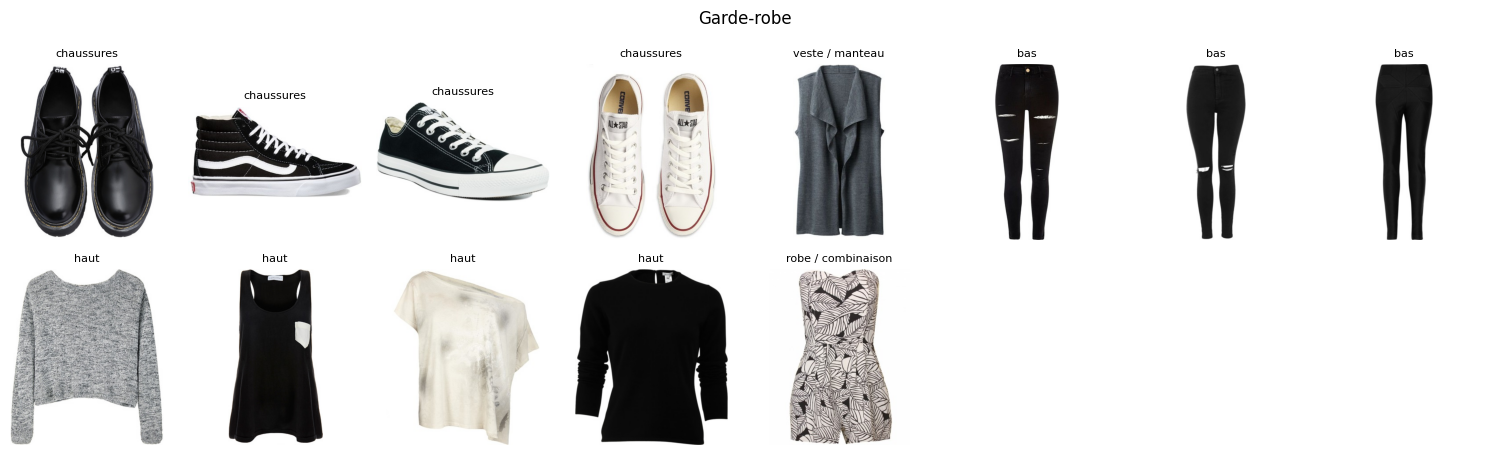

,emplacement,possédées,meilleur_gain,gain_moyen
5,sac,0,12,1.271429
4,chaussures,4,11,2.463768
3,veste / manteau,1,10,1.210526
1,bas,3,7,1.510638
0,haut,4,6,0.964912
2,robe / combinaison,1,4,1.481481
6,accessoire,0,0,0.000000


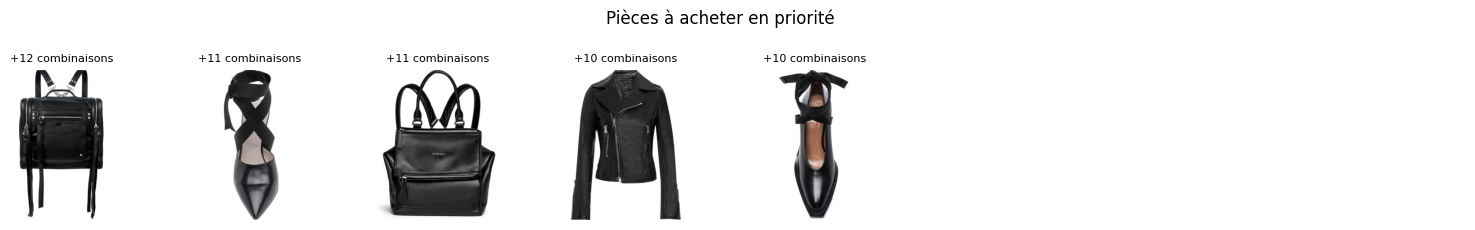

,achat,pièce,catégorie,combinaisons après achat
0,1,sac,Bags,25
1,2,chaussures,Shoes,46
2,3,veste / manteau,Outwear,70
3,4,haut,Tops,104
4,5,bas,Skirts,146


In [36]:
from PIL import Image as PILImage
def show_items(rows, titles, suptitle, n_col=8):
    rows = list(rows); n = len(rows); nr = max(1, math.ceil(n / n_col))
    fig, axs = plt.subplots(nr, n_col, figsize=(1.9 * n_col, 2.3 * nr)); axs = np.atleast_1d(axs).ravel()
    for a in axs: a.axis('off')
    for a, r, t in zip(axs, rows, titles):
        p = items['path'][r]
        try: a.imshow(PILImage.open(p).convert('RGB'))
        except Exception: a.text(.5, .5, CAT_ARR[r], ha='center')
        a.set_title(t, fontsize=8)
    fig.suptitle(suptitle); savefig(f"demo_{re.sub(r'[^a-z]+', '_', suptitle.lower())[:30]}.png")

w = sorted(WARDS[:50], key=lambda w: GapScene(w['W'], w['C'][:1]).combos(np.arange(len(w['W'])))[1])[len(WARDS[:50]) // 3]
sc = GapScene(w['W'], np.r_[w['C'], np.random.RandomState(5).choice(te_items, min(300, len(te_items)), replace=False)])
sc = GapScene(w['W'], np.array([r for r in dict.fromkeys(sc.C) if r not in set(w['W'])]))
b0, t0_ = sc.combos(np.arange(sc.nW))
print(f'Garde-robe : {sc.nW} pièces | tenues de base : {b0} | combinaisons : {t0_}')
show_items(sc.W, [SLOT_FR[SLOT_ARR[r]] for r in sc.W], 'Garde-robe')
display(sc.slot_report())
cand, g, _ = sc.rank(); top = cand[:5]
price = items['price'].to_numpy()
titles = [f"+{int(gg)} combinaisons" + (f"\n{price[sc.rows[c]]:.0f} $" if price[sc.rows[c]] == price[sc.rows[c]] else '')
          for c, gg in zip(top, g[:5])]
show_items(sc.rows[top], titles, 'Pièces à acheter en priorité')
picks, hist = sc.greedy(K_BUY)
DEMO_DF = pd.DataFrame({'achat': range(1, len(picks) + 1), 'pièce': [SLOT_FR[SLOT_ARR[sc.rows[k]]] for k in picks],
                        'catégorie': [CAT_ARR[sc.rows[k]] for k in picks], 'combinaisons après achat': hist[1:]})
display(DEMO_DF)

## 9.b Radiographie de la garde-robe : ce que je possède déjà

Le **gain** mesure ce qu'une pièce *apporterait*. Son miroir exact mesure ce qu'une pièce *apporte déjà* :

> **contribution(p) = combinaisons(W) − combinaisons(W sans p)**

Une pièce de contribution **0** est un **poids mort** : elle ne forme aucune tenue avec le reste. C'est l'argument d'Amine (« ne pas gaspiller ») : avant d'acheter, il faut savoir quoi *ne pas racheter*, voire revendre.
Couleurs : **rouge** = poids mort, **or** = pièce-étoile (20 % les plus contributrices), **gris** = non comptée (accessoire).


,emplacement,catégorie,tenues_perdues_si_retirée
0,chaussures,Shoes,6
9,haut,Tops,6
11,haut,Tops,6
5,bas,Pants,6
1,chaussures,Shoes,5
6,bas,Pants,4
7,bas,Pants,2
2,chaussures,Shoes,2


Garde-robe démo : 13 pièces comptées | poids morts : 4 (31%) | combinaisons : 13


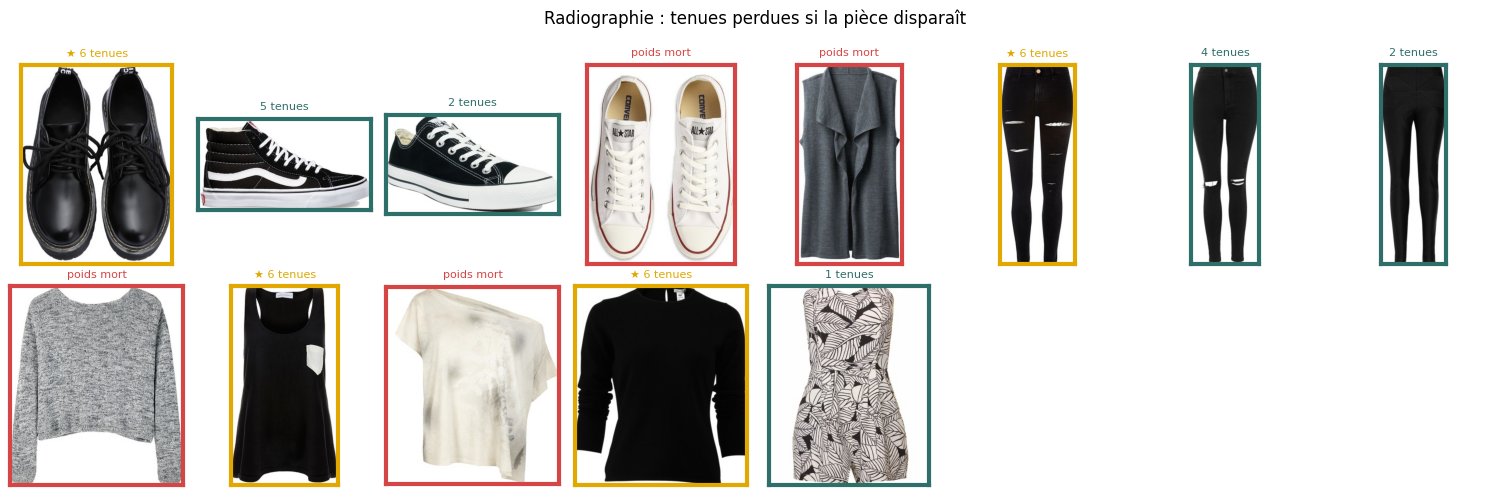

Sur 80 garde-robes simulées : 30.5% des pièces comptées ne créent AUCUNE tenue (poids mort).


In [37]:
from PIL import Image as PILImage
COUNTED = {'top', 'bottom', 'onepiece', 'outer', 'shoes', 'bag'}

def xray(sc):
    own = np.arange(sc.nW); tot = sc.combos(own)[1]
    contrib = np.array([tot - sc.combos(np.delete(own, k))[1] for k in range(sc.nW)])
    return tot, contrib

def show_xray(sc, contrib, n_col=8):
    rows = sc.rows[:sc.nW]; n = len(rows); nr = max(1, math.ceil(n / n_col))
    fig, axs = plt.subplots(nr, n_col, figsize=(1.9 * n_col, 2.5 * nr)); axs = np.atleast_1d(axs).ravel()
    for a in axs: a.axis('off')
    pos = contrib[contrib > 0]; star = np.quantile(pos, .8) if len(pos) else np.inf
    for a, r, c in zip(axs, rows, contrib):
        try: a.imshow(PILImage.open(items['path'][r]).convert('RGB'))
        except Exception: a.text(.5, .5, CAT_ARR[r], ha='center')
        if SLOT_ARR[r] not in COUNTED: col, t = '#9aa0a6', 'non comptée'
        elif c == 0: col, t = '#D64545', 'poids mort'
        elif c >= star: col, t = '#E0A800', f'★ {int(c)} tenues'
        else: col, t = '#2F6F6A', f'{int(c)} tenues'
        a.axis('on'); a.set_xticks([]); a.set_yticks([]); a.set_title(t, fontsize=8, color=col)
        for s in a.spines.values(): s.set_edgecolor(col); s.set_linewidth(3)
    fig.suptitle('Radiographie : tenues perdues si la pièce disparaît'); savefig('radiographie_garde_robe.png')

tot_x, contrib = xray(sc)
own_rows = sc.rows[:sc.nW]; counted = np.array([SLOT_ARR[r] in COUNTED for r in own_rows]); dead = counted & (contrib == 0)
XRAY_DF = pd.DataFrame(dict(emplacement=[SLOT_FR[SLOT_ARR[r]] for r in own_rows], catégorie=[CAT_ARR[r] for r in own_rows],
                            tenues_perdues_si_retirée=contrib)).sort_values('tenues_perdues_si_retirée', ascending=False)
display(XRAY_DF.head(8))
print(f'Garde-robe démo : {counted.sum()} pièces comptées | poids morts : {dead.sum()} ({dead.sum() / max(1, counted.sum()):.0%}) | combinaisons : {tot_x}')
show_xray(sc, contrib)

# Sur toutes les garde-robes simulées : quelle part des pièces ne crée aucune tenue ?
N_XRAY = 20 if SMOKE_TEST else 80
dead_n = tot_n = 0; stars_share = []
for w_ in WARDS[:N_XRAY]:
    s_ = GapScene(w_['W'], w_['C'][:1]); t_, c_ = xray(s_)
    m_ = np.array([SLOT_ARR[r] in COUNTED for r in s_.rows[:s_.nW]])
    dead_n += int((m_ & (c_ == 0)).sum()); tot_n += int(m_.sum())
DEAD_RATE = dead_n / max(1, tot_n)
print(f'Sur {N_XRAY} garde-robes simulées : {DEAD_RATE:.1%} des pièces comptées ne créent AUCUNE tenue (poids mort).')


## 9.c Lentille persona : le même manque, trois réponses

Les trois personas du cahier des charges n'achètent pas pour la même raison. On part du **même gain en combinaisons** et on le pondère :

| Persona | Moteur | Score |
|---|---|---|
| **Amine** (budget serré) | rentabilité | gain ÷ prix en **TND** (« tenues pour 100 TND ») |
| **Yasmine** (matins rapides) | polyvalence | gain × part de la garde-robe avec laquelle la pièce va |
| **Sami** (marque personnelle) | signature | gain × cohérence de style² (proximité au « centre » de sa garde-robe) |

Si les trois listes de recommandations étaient identiques, la personnalisation ne servirait à rien. On le **mesure** (indice de Jaccard entre les top-5).


Prix réels dans les données : False | sinon prix par emplacement (hypothèse, voir PRICE_TIER_TND)


,persona,emplacement,catégorie,gain,prix_TND,pourquoi
0,Amine · économie,haut,Tops,6,45,13.3 tenues / 100 TND
1,Yasmine · efficacité,chaussures,Shoes,11,140,va avec 78% de la garde-robe
2,Sami · signature,haut,Tops,6,45,cohérence 0.50
3,Neutre · gain brut,sac,Bags,12,120,gain brut maximal


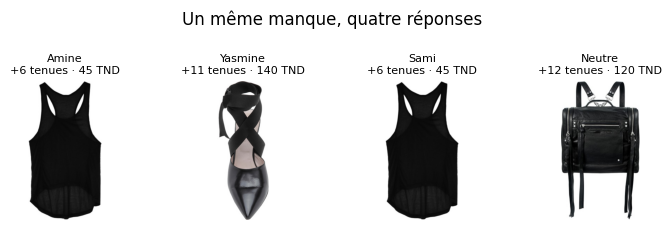

,Jaccard top-5 moyen
Amine · économie vs Yasmine · efficacité,0.61
Amine · économie vs Sami · signature,0.50
Amine · économie vs Neutre · gain brut,0.63
Yasmine · efficacité vs Sami · signature,0.67
Yasmine · efficacité vs Neutre · gain brut,0.86
Sami · signature vs Neutre · gain brut,0.63


Jaccard = 1 : listes identiques | 0 : aucune pièce en commun. Plus c'est bas, plus la lentille persona change la recommandation.


In [38]:
PRICE = items['price'].to_numpy(dtype=float)
PRICE_MED = float(np.nanmedian(PRICE)) if np.isfinite(PRICE).any() else 50.0
# Re-PolyVore (version dossiers) ne contient AUCUN prix : sans correction tous les prix valent la même médiane, donc « Amine » = « Neutre ».
# Repli : prix typique par emplacement, en TND. Ce sont des HYPOTHÈSES à remplacer par des prix relevés dans des boutiques tunisiennes.
PRICE_TIER_TND = {'top': 45, 'bottom': 80, 'onepiece': 110, 'outer': 180, 'shoes': 140, 'bag': 120, 'accessory': 35}
HAS_REAL_PRICE = bool(np.isfinite(PRICE).any())
def price_tnd(rows):
    rows = np.asarray(rows, int); tier = np.array([PRICE_TIER_TND[SLOT_ARR[r]] for r in rows], float)
    return np.maximum(np.where(np.isfinite(PRICE[rows]), PRICE[rows] * USD_TND, tier), 1.0)
print('Prix réels dans les données :', HAS_REAL_PRICE, '| sinon prix par emplacement (hypothèse, voir PRICE_TIER_TND)')

def persona_features(sc):
    cand, g, mp = sc.gains(); rows_c = sc.rows[cand]; own = sc.rows[:sc.nW]
    p = price_tnd(rows_c)
    diff = sc.slots[cand][:, None] != sc.slots[:sc.nW][None, :]
    vers = ((sc.B[np.ix_(cand, np.arange(sc.nW))]) & diff).sum(1) / np.maximum(diff.sum(1), 1)
    cen = l2n(Z[own].mean(0, keepdims=True))[0]; coh = Z[rows_c] @ cen
    cohn = (coh - coh.min()) / (np.ptp(coh) + 1e-9)
    return dict(cand=cand, g=g.astype(float), p=p, vers=vers, coh=coh, cohn=cohn, mp=mp)

def persona_scores(f):
    t = 1e-6 * f['mp']
    return {'Amine · économie': f['g'] / f['p'] + t, 'Yasmine · efficacité': f['g'] * f['vers'] + t,
            'Sami · signature': f['g'] * f['cohn'] ** 2 + t, 'Neutre · gain brut': f['g'] + t}

f = persona_features(sc); S = persona_scores(f); lines, picks_, titles_ = [], [], []
for name, s in S.items():
    k = int(np.argmax(s)); r = sc.rows[f['cand'][k]]
    why = {'Amine': f"{100 * f['g'][k] / f['p'][k]:.1f} tenues / 100 TND", 'Yasmine': f"va avec {f['vers'][k]:.0%} de la garde-robe",
           'Sami': f"cohérence {f['coh'][k]:.2f}", 'Neutre': 'gain brut maximal'}[name.split(' ')[0]]
    lines.append(dict(persona=name, emplacement=SLOT_FR[SLOT_ARR[r]], catégorie=CAT_ARR[r], gain=int(f['g'][k]),
                      prix_TND=round(float(f['p'][k])), pourquoi=why))
    picks_.append(r); titles_.append(f"{name.split(' · ')[0]}\n+{int(f['g'][k])} tenues · {f['p'][k]:.0f} TND")
PERSONA_DF = pd.DataFrame(lines); display(PERSONA_DF)
show_items(picks_, titles_, 'Un même manque, quatre réponses', n_col=4)

N_LENS = 15 if SMOKE_TEST else 40
jac = defaultdict(list)
for w_ in WARDS[:N_LENS]:
    f_ = persona_features(GapScene(w_['W'], w_['C'])); ts = {n: set(f_['cand'][np.argsort(-s_)[:5]].tolist()) for n, s_ in persona_scores(f_).items()}
    nm = list(ts)
    for i_ in range(len(nm)):
        for j_ in range(i_ + 1, len(nm)): jac[(nm[i_], nm[j_])].append(len(ts[nm[i_]] & ts[nm[j_]]) / max(1, len(ts[nm[i_]] | ts[nm[j_]])))
JAC_DF = pd.Series({f'{a}  vs  {b}': np.mean(v) for (a, b), v in jac.items()}, name='Jaccard top-5 moyen').round(2)
display(JAC_DF.to_frame()); print('Jaccard = 1 : listes identiques | 0 : aucune pièce en commun. Plus c\'est bas, plus la lentille persona change la recommandation.')


## 9.d La pièce fantôme : dessiner ce qui manque

Jusqu'ici on **teste chaque article** du magasin. Avec un vrai catalogue (des dizaines de milliers de pièces), c'est lent, et surtout on ne **voit** pas ce qu'on cherche.

**Idée :** le modèle de compatibilité est une régression logistique, donc **dérivable**. On peut donc *optimiser directement* le vecteur z (dans l'espace ACP) qui maximise la compatibilité moyenne avec ta garde-robe pour un emplacement donné : la **pièce fantôme**. Puis :
1. **Description** : on la ramène dans l'espace FashionCLIP et on trouve la phrase la plus proche (« navy blue trousers »), grâce au texte.
2. **Retrouvailles** : on cherche dans le catalogue les vrais articles les plus proches du fantôme.

**Test honnête :** la pièce fantôme est-elle un bon *raccourci* de la recherche exhaustive ? Pour chaque garde-robe simulée, on prend l'emplacement qui a le meilleur gain, puis on compare le gain de l'article le plus proche du fantôme à celui de tous les articles du même emplacement (percentile ; hasard = 0,5). On compare aussi à l'article proche de la **pièce moyenne** (sans optimisation) pour prouver que l'optimisation apporte quelque chose.


Pièces fantômes SANS correction (lam=0) : ['black cardigan', 'black jumpsuit', 'black flats', 'black tank top', 'black skirt']
Pièces fantômes AVEC correction (lam=0,5) : ['black denim jacket', 'black shirt', 'black tote bag', 'black dress', 'black heels']


,emplacement,pièce fantôme (texte),gain de l'article le plus proche,meilleur gain possible (exhaustif)
0,veste / manteau,black denim jacket,10,10
1,haut,black shirt,6,6
2,sac,black tote bag,5,12
3,robe / combinaison,black dress,4,4
4,chaussures,black heels,3,11


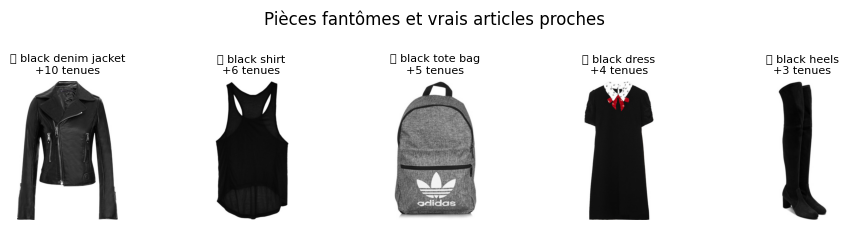

Part de pièces fantômes de couleur neutre (noir/blanc/gris/beige) : corrigé 54% | sans correction 56% | taux de base de la liste de couleurs : 36%


,percentile médian du gain,part dans le top 10 %,n
fantôme corrigé,0.933,0.750,80.0
fantôme sans correction,0.929,0.700,80.0
pièce moyenne (sans optimisation),0.375,0.125,80.0
hasard (théorique),0.500,0.100,NaN


Temps cumulé : recherche exhaustive 2.9s | fantôme (1 emplacement) 5.7s. Le coût exhaustif croît avec la taille du catalogue (100 articles ici), celui du fantôme reste une optimisation + un produit scalaire.


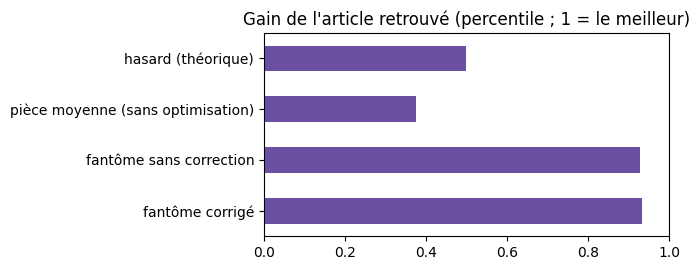

In [39]:
GARMENTS = {'top': ['t-shirt', 'blouse', 'shirt', 'sweater', 'knit top', 'hoodie', 'tank top'],
            'bottom': ['jeans', 'trousers', 'skirt', 'shorts', 'leggings', 'wide-leg pants'],
            'onepiece': ['dress', 'jumpsuit', 'maxi dress', 'shirt dress'],
            'outer': ['blazer', 'denim jacket', 'coat', 'leather jacket', 'cardigan', 'trench coat'],
            'shoes': ['sneakers', 'boots', 'sandals', 'heels', 'loafers', 'flats'],
            'bag': ['tote bag', 'backpack', 'crossbody bag', 'clutch']}
COLORS = ['black', 'white', 'beige', 'navy blue', 'grey', 'brown', 'red', 'green', 'blue denim', 'pink', 'camel']
PCA_SCALE = float(np.linalg.norm(pca.transform(EMB[:5000]), axis=1).mean())   # pour revenir de l'ACP normalisée vers l'espace CLIP
_TXT = {}

def ghost_text(z, slot):
    if slot not in GARMENTS: return slot
    if slot not in _TXT:
        pr = [(c, x) for x in GARMENTS[slot] for c in COLORS]
        _TXT[slot] = (pr, encode_texts([f'a photo of a {c} {x}' for c, x in pr]))
    pr, T_ = _TXT[slot]
    e = l2n(pca.inverse_transform((z * PCA_SCALE)[None, :]))[0]
    c, x = pr[int(np.argmax(T_ @ e))]
    return f'{c} {x}'

def ghost_for_slot(sc, cand, slot, steps=120, lr=0.08, lam=0.5):
    # montée de gradient sur la sphère unité. lam = 0 : maximise la probabilité moyenne (tend vers la pièce « neutre qui va avec tout »)
    # lam > 0 : maximise le logit moyen MOINS lam × la compatibilité moyenne avec un partenaire quelconque (pièce SPÉCIFIQUE à cette garde-robe)
    own = sc.rows[:sc.nW]; partners = own[SLOT_ARR[own] != slot]; pool = cand[sc.slots[cand] == slot]
    if len(partners) == 0 or len(pool) == 0: return None
    zw = Z[partners]; sid = SLOT_ID[partners]; oh_idx = PAIR_ID[SLOTS.index(slot), sid]; wslot = np.bincount(sid, minlength=NS) / len(sid)
    coef, b, D = COMPAT.coef_[0], COMPAT.intercept_[0], Z.shape[1]; refZ = Z[REF_ROWS]
    z0 = l2n(Z[sc.rows[pool]].mean(0, keepdims=True))[0]; z = z0.copy()
    for t in range(steps):
        d = z[None, :] - zw; dlog = coef[:D] * zw + coef[D:2 * D] * np.sign(d)
        if lam == 0:
            logit = (coef[:D] * z[None, :] * zw).sum(1) + (coef[D:2 * D] * np.abs(d)).sum(1) + coef[2 * D + oh_idx] + b
            p = 1 / (1 + np.exp(-logit)); grad = ((p * (1 - p))[:, None] * dlog).mean(0)
        else:
            grad = dlog.mean(0)
            for k in range(NS):
                if wslot[k] > 0 and (REF_SLOT == k).any():
                    R_ = refZ[REF_SLOT == k]; grad = grad - lam * wslot[k] * (coef[:D] * R_ + coef[D:2 * D] * np.sign(z[None, :] - R_)).mean(0)
        step = lr * (1 - t / steps) + 0.005
        z = l2n((z + step * grad / (np.linalg.norm(grad) + 1e-12))[None, :])[0]
    Zp = Z[sc.rows[pool]]
    return dict(z=z, z0=z0, pool=pool, nn=pool[int(np.argmax(Zp @ z))], nn0=pool[int(np.argmax(Zp @ z0))])

def ghost_report(sc, k=5, lam=0.5):
    cand, g, _ = sc.gains(); gm = dict(zip(cand.tolist(), g.tolist())); out = []
    for s in ['top', 'bottom', 'onepiece', 'outer', 'shoes', 'bag']:
        r = ghost_for_slot(sc, cand, s, lam=lam)
        if r is None: continue
        out.append(dict(slot=s, description=ghost_text(r['z'], s), nn=int(r['nn']), unlocked=int(gm[int(r['nn'])]),
                        best_in_slot=int(max(gm[int(c)] for c in r['pool']))))
    return pd.DataFrame(out).sort_values('unlocked', ascending=False).head(k).reset_index(drop=True)

GR_RAW = ghost_report(sc, 5, lam=0.0); GR = ghost_report(sc, 5, lam=0.5)
print('Pièces fantômes SANS correction (lam=0) :', list(GR_RAW['description']))
print('Pièces fantômes AVEC correction (lam=0,5) :', list(GR['description']))
display(GR.assign(emplacement=GR['slot'].map(SLOT_FR))[['emplacement', 'description', 'unlocked', 'best_in_slot']]
        .rename(columns={'description': 'pièce fantôme (texte)', 'unlocked': 'gain de l\'article le plus proche', 'best_in_slot': 'meilleur gain possible (exhaustif)'}))
show_items(sc.rows[GR['nn'].to_numpy()], [f"👻 {d}\n+{u} tenues" for d, u in zip(GR['description'], GR['unlocked'])], 'Pièces fantômes et vrais articles proches', n_col=5)

# ---- Validation : le fantôme est-il un bon raccourci de la recherche exhaustive ? ----
N_GHOST = 20 if SMOKE_TEST else 80
grec = defaultdict(list); NEUT = defaultdict(list); t_ex = t_gh = 0.0
for w_ in WARDS[:N_GHOST]:
    sc_ = GapScene(w_['W'], w_['C'])
    t0 = time.perf_counter(); cand_, g_, _ = sc_.gains(); t_ex += time.perf_counter() - t0
    if g_.max() <= 0: continue
    slot_ = sc_.slots[cand_][int(np.argmax(g_))]
    t0 = time.perf_counter(); r = ghost_for_slot(sc_, cand_, slot_, lam=0.5); t_gh += time.perf_counter() - t0
    r0 = ghost_for_slot(sc_, cand_, slot_, lam=0.0)
    if r is None: continue
    NEUT['corrigé'].append(ghost_text(r['z'], slot_).split(' ')[0] in {'black', 'white', 'grey', 'beige'}); NEUT['sans correction'].append(ghost_text(r0['z'], slot_).split(' ')[0] in {'black', 'white', 'grey', 'beige'})
    gm = dict(zip(cand_.tolist(), g_.tolist())); gp = np.array([gm[int(k)] for k in r['pool']])
    mid = lambda x, gp=gp: float((gp < x).mean() + 0.5 * (gp == x).mean())
    grec['fantôme corrigé'].append(mid(gm[int(r['nn'])])); grec['fantôme sans correction'].append(mid(gm[int(r0['nn'])])); grec['pièce moyenne (sans optimisation)'].append(mid(gm[int(r['nn0'])]))
GHOST_EVAL = pd.DataFrame({m: {'percentile médian du gain': np.median(v), 'part dans le top 10 %': np.mean(np.array(v) >= .9), 'n': len(v)}
                           for m, v in grec.items()}).T.round(3)
GHOST_EVAL.loc['hasard (théorique)'] = [0.5, 0.1, np.nan]
print('Part de pièces fantômes de couleur neutre (noir/blanc/gris/beige) : ' + ' | '.join(f'{k} {np.mean(v):.0%}' for k, v in NEUT.items()) + f' | taux de base de la liste de couleurs : {4 / len(COLORS):.0%}')
display(GHOST_EVAL); GHOST_EVAL.to_csv(WORK / 'evaluation_piece_fantome.csv')
print(f'Temps cumulé : recherche exhaustive {t_ex:.1f}s | fantôme (1 emplacement) {t_gh:.1f}s. '
      f'Le coût exhaustif croît avec la taille du catalogue ({N_CANDIDATES} articles ici), celui du fantôme reste une optimisation + un produit scalaire.')
GHOST_EVAL['percentile médian du gain'].plot.barh(figsize=(7, 2.8), color='#6B4FA3', title='Gain de l\'article retrouvé (percentile ; 1 = le meilleur)')
plt.xlim(0, 1); savefig('evaluation_piece_fantome.png')


## 9.e Où est le trou : été ou hiver ? (contexte tunisien)

Une garde-robe peut offrir 30 tenues… dont 28 pour l'été. On étiquette chaque article en **zéro-shot FashionCLIP** (*chaud*, *froid*, *mi-saison*) et on recompte les combinaisons **par saison** (une pièce *mi-saison* sert aux deux). Le trou saisonnier est la saison qui offre le moins de tenues.

*Limite :* ces étiquettes ne sont pas validées par des annotateurs (à vérifier à la main sur ~50 articles avant de les citer comme un résultat).


Répartition des saisons (zéro-shot) : {'chaud': 77730, 'mi-saison': 34609, 'froid': 14313}


,pièces,combinaisons,meilleur_gain_possible
saison,,,
chaud,13,13,12
froid,6,3,3


Trou saisonnier de la garde-robe démo : « froid » (3 combinaisons).


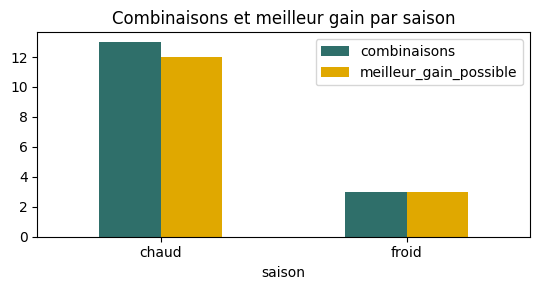

In [40]:
SEASON_TXT = {'chaud': 'a photo of light summer clothing for hot weather',
              'froid': 'a photo of warm winter clothing for cold weather',
              'mi-saison': 'a photo of mid-season clothing for mild weather'}
T_s = encode_texts(list(SEASON_TXT.values()))
SEASON_ARR = np.array(list(SEASON_TXT))[(EMB @ T_s.T).argmax(1)]
print('Répartition des saisons (zéro-shot) :', dict(Counter(map(str, SEASON_ARR))))

def season_report(sc):
    own = np.arange(sc.nW); cand = np.arange(sc.nW, len(sc.rows)); rows = []
    for s in ['chaud', 'froid']:
        ok_o = np.isin(SEASON_ARR[sc.rows[own]], [s, 'mi-saison']); idx = own[ok_o]
        cm = cand[np.isin(SEASON_ARR[sc.rows[cand]], [s, 'mi-saison'])]
        t0 = sc.combos(idx)[1] if len(idx) else 0
        gains = [sc.combos(np.r_[idx, k])[1] - t0 for k in cm]
        rows.append(dict(saison=s, pièces=len(idx), combinaisons=t0, meilleur_gain_possible=int(max(gains)) if gains else 0))
    return pd.DataFrame(rows).set_index('saison')

SEASON_DF = season_report(sc); display(SEASON_DF)
low = SEASON_DF['combinaisons'].idxmin(); print(f"Trou saisonnier de la garde-robe démo : « {low} » ({int(SEASON_DF.loc[low, 'combinaisons'])} combinaisons).")
SEASON_DF[['combinaisons', 'meilleur_gain_possible']].plot.bar(figsize=(5.5, 3), color=['#2F6F6A', '#E0A800'], title='Combinaisons et meilleur gain par saison', rot=0)
savefig('trou_saisonnier.png')


## 9.f Robustesse : le classement dépend-il du seuil τ ?

Le seuil τ transforme une probabilité en « va / ne va pas ensemble ». Si le classement des pièces à acheter changeait complètement avec τ ± 0,10, la recommandation serait fragile. Deux contrôles :
- **Spearman** entre le classement des gains au τ de référence et celui obtenu avec τ − 0,10, τ + 0,10 ;
- **comptage souple** : au lieu de couper à τ, on additionne les probabilités (nombre *espéré* de tenues). Aucun seuil.


In [41]:
from scipy.stats import spearmanr

def count_combos_soft(slots, P):
    # même logique que count_combos, mais avec des probabilités (produit) au lieu de booléens (ET)
    idx = {s: np.where(slots == s)[0] for s in SLOTS}; total = 0.0
    for pat in CORE:
        ids = [idx[s] for s in pat]
        if any(len(x) == 0 for x in ids): continue
        k = len(pat); V = np.ones([len(x) for x in ids])
        for a in range(k):
            for b in range(a + 1, k):
                sh = [1] * k; sh[a] = len(ids[a]); sh[b] = len(ids[b]); V = V * P[np.ix_(ids[a], ids[b])].reshape(sh)
        mult = np.ones(V.shape)
        for L in LAYERS:
            l = idx[L]
            if len(l) == 0: continue
            ok = np.ones((len(l),) + V.shape)
            for a in range(k):
                sh = [len(l)] + [1] * k; sh[a + 1] = len(ids[a]); ok = ok * P[np.ix_(l, ids[a])].reshape(sh)
            mult = mult * (1 + (ok.sum(0) if LAYER_MODE == 'mult' else 1 - np.prod(1 - ok, axis=0)))
        total += float((V * mult).sum())
    return total

def gains_variant(sc, mode, tau=None):
    own = np.arange(sc.nW); cand = np.arange(sc.nW, len(sc.rows))
    if mode == 'hard':
        M = sc.P >= tau; f_ = lambda loc: count_combos(sc.slots[loc], M[np.ix_(loc, loc)])[1]
    else:
        f_ = lambda loc: count_combos_soft(sc.slots[loc], sc.P[np.ix_(loc, loc)])
    t0 = f_(own); return np.array([f_(np.r_[own, k]) - t0 for k in cand])

VARIANTS = {'τ − 0,10': ('hard', TAU - .10), 'τ (référence)': ('hard', TAU), 'τ + 0,10': ('hard', TAU + .10), 'comptage souple': ('soft', None)}
N_STAB = 15 if SMOKE_TEST else 60
rho, top5 = defaultdict(list), defaultdict(list)
for w_ in WARDS[:N_STAB]:
    sc_ = GapScene(w_['W'], w_['C']); G = {n: gains_variant(sc_, m, t) for n, (m, t) in VARIANTS.items()}; ref = G['τ (référence)']
    for n, gv in G.items():
        if n == 'τ (référence)': continue
        if np.ptp(ref) > 0 and np.ptp(gv) > 0: rho[n].append(spearmanr(ref, gv)[0])
        top5[n].append(len(set(np.argsort(-ref)[:5]) & set(np.argsort(-gv)[:5])) / 5)
STAB_DF = pd.DataFrame({'Spearman moyen': {n: np.mean(v) for n, v in rho.items()}, 'recouvrement top-5': {n: np.mean(v) for n, v in top5.items()}}).round(2)
display(STAB_DF); STAB_DF.to_csv(WORK / 'stabilite_seuil.csv')


,Spearman moyen,recouvrement top-5
"τ − 0,10",0.64,0.39
"τ + 0,10",0.54,0.42
comptage souple,0.67,0.56


## 9.g Juge indépendant : ne pas se noter soi-même

Le test « combinaisons après K achats » (section 8) est **circulaire** : le panier est choisi avec le modèle de compatibilité *puis* évalué avec le même modèle. On casse la circularité avec un **second modèle indépendant** : un *gradient boosting* entraîné sur les mêmes paires, avec **d'autres variables** (somme et écart des embeddings au lieu du produit). Les paniers sont choisis avec le modèle 1, **jugés par le modèle 2**.
Si la méthode reste meilleure que les références quand elle est jugée par un autre modèle, le gain ne vient pas d'un biais du premier.


Juge entraîné en 33s | AUC paires (test) : juge 0.638 | modèle 1 0.652 | τ_juge = 0.503


,panier glouton (choisi par le modèle 1),similarité,emplacement le plus rare,hasard
achats,,,,
0,21.8,21.8,21.8,21.8
1,30.5,26.3,26.1,22.4
2,40.2,30.9,28.1,22.9
3,51.1,36.7,30.9,24.0
4,61.7,42.9,33.6,26.0
5,72.6,48.1,36.3,26.8


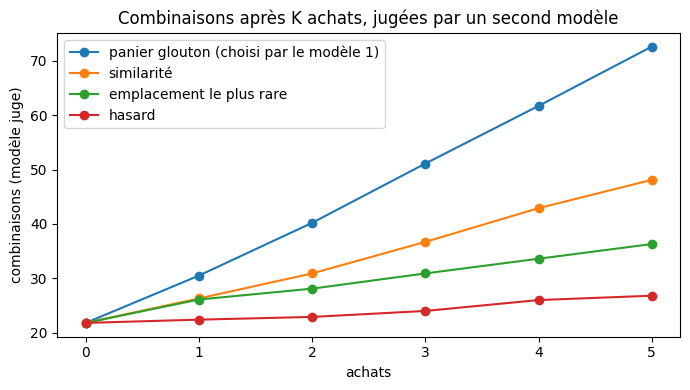

In [42]:
from sklearn.ensemble import HistGradientBoostingClassifier

def judge_feats(i, j):
    i, j = np.asarray(i), np.asarray(j)
    oh = np.zeros((len(i), N_PAIR_TYPES), np.float32); oh[np.arange(len(i)), PAIR_ID[SLOT_ID[i], SLOT_ID[j]]] = 1
    return np.hstack([Z[i] + Z[j], np.abs(Z[i] - Z[j]), oh])

t0 = time.time(); sel = np.random.RandomState(0).permutation(len(y_tr))[:80_000]
JUDGE = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, random_state=SEED).fit(judge_feats(I_tr[sel], J_tr[sel]), y_tr[sel])
pj_va = JUDGE.predict_proba(judge_feats(I_va, J_va))[:, 1]; fpr_j, tpr_j, thr_j = roc_curve(y_va, pj_va); TAU_J = float(thr_j[np.argmax(tpr_j - fpr_j)])
AUC_J = roc_auc_score(y_te, JUDGE.predict_proba(judge_feats(I_te, J_te))[:, 1]); AUC_LR = roc_auc_score(y_te, p_te)
print(f'Juge entraîné en {time.time() - t0:.0f}s | AUC paires (test) : juge {AUC_J:.3f} | modèle 1 {AUC_LR:.3f} | τ_juge = {TAU_J:.3f}')

def judge_matrix(rows):
    rows = np.asarray(rows); n = len(rows); P = np.zeros((n, n), np.float32); a, b = np.triu_indices(n, 1)
    if len(a): P[a, b] = P[b, a] = JUDGE.predict_proba(judge_feats(rows[a], rows[b]))[:, 1]
    return P

N_JUDGE = 12 if SMOKE_TEST else 60; jc = defaultdict(list); rg = np.random.RandomState(21)
for w_ in WARDS[:N_JUDGE]:
    sc_ = GapScene(w_['W'], w_['C']); nW = sc_.nW; cand = np.arange(nW, len(sc_.rows)); W = np.array(w_['W']); rows_c = sc_.rows[cand]
    BJ = judge_matrix(sc_.rows) >= TAU_J
    jcount = lambda loc: count_combos(sc_.slots[np.asarray(loc, int)], BJ[np.ix_(np.asarray(loc, int), np.asarray(loc, int))])[1]
    simv = (Z[rows_c] @ Z[W].T).mean(1); cnt = Counter(SLOT_ARR[W])
    rare = np.array([-cnt.get(SLOT_ARR[r], 0) if SLOT_ARR[r] in CORE_SLOTS | {'outer', 'bag'} else -99 for r in rows_c], float)
    picks, _ = sc_.greedy(K_BUY); picks = list(picks) + [picks[-1]] * (K_BUY - len(picks)) if picks else []
    orders = {'panier glouton (choisi par le modèle 1)': picks, 'similarité': list(cand[np.argsort(-simv)]),
              'emplacement le plus rare': list(cand[np.argsort(-(rare + 1e-3 * simv))]), 'hasard': list(cand[rg.permutation(len(cand))])}
    for m, order in orders.items():
        if not order: continue
        jc[m].append([jcount(np.r_[np.arange(nW), order[:k]]) for k in range(K_BUY + 1)])
JUDGE_DF = pd.DataFrame({m: np.mean(v, 0) for m, v in jc.items()}, index=pd.Index(range(K_BUY + 1), name='achats')).round(1)
display(JUDGE_DF); JUDGE_DF.to_csv(WORK / 'combinaisons_jugees_par_second_modele.csv')
ax = JUDGE_DF.plot(marker='o', figsize=(7, 4), title='Combinaisons après K achats, jugées par un second modèle'); ax.set_ylabel('combinaisons (modèle juge)')
savefig('combinaisons_juge_independant.png')


## 10. Export

In [43]:
import joblib
joblib.dump(dict(pca=pca, compat=COMPAT, tau=TAU, slots=SLOTS, slot_of=SLOT_OF, cats20=CATS20, core=CORE, layers=LAYERS,
                 pair_id=PAIR_ID, model_name=MODEL_NAME), ART / 'gap_detector.joblib')
SUMMARY = dict(format=FORMAT, n_items=int(len(items)), n_outfits=int(len(OUTFIT_ROWS)), tau=TAU,
               compatibility=COMPAT_DF.reset_index().to_dict('records'), evaluation=EVAL_DF.reset_index().to_dict('records'),
               curve=CURVE_DF.reset_index().to_dict('records'), real_outfits_valid=float(rec), shuffled_outfits_valid=float(rec_f),
               smoke_test=SMOKE_TEST)
json.dump(SUMMARY, open(WORK / 'resume_objectif4.json', 'w', encoding='utf-8'), indent=1, ensure_ascii=False, default=float)
print('Exporté dans', WORK.resolve()); [print('  ', p.relative_to(WORK)) for p in sorted(WORK.rglob('*')) if p.is_file() and 'data' not in p.parts]

Exporté dans /content/dressme_obj4
   ablation_evaluation_exigeante.csv
   artifacts/fashionclip_obj4.npz
   artifacts/gap_detector.joblib
   auc_par_type_de_paire.csv
   combinaisons_jugees_par_second_modele.csv
   combinaisons_vs_achats.csv
   compatibilite.csv
   evaluation_modele_compatibilite.csv
   evaluation_piece_fantome.csv
   evaluation_piece_manquante.csv
   figures/combinaisons_juge_independant.png
   figures/combinaisons_vs_achats.png
   figures/compatibilite_distribution.png
   figures/demo_garde_robe.png
   figures/demo_pi_ces_acheter_en_priorit_.png
   figures/demo_pi_ces_fant_mes_et_vrais_artic.png
   figures/demo_un_m_me_manque_quatre_r_ponses.png
   figures/eda_categories_emplacements.png
   figures/entrainement_courbes.png
   figures/evaluation_hit10.png
   figures/evaluation_piece_fantome.png
   figures/pieces_les_plus_promiscues.png
   figures/promiscuite_avant_apres.png
   figures/radiographie_garde_robe.png
   figures/trou_saisonnier.png
   resume_objectif4.json

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

## 10.b Export pour l'application

L'écran **Gaps** de l'interface attend, pour chaque pièce manquante : `description`, `category`, `unlockedOutfits`. On exporte donc la sortie de la pièce fantôme dans ce format (`gap_report.json`), plus un `slot` précis (la catégorie de l'interface regroupe robe et haut) et l'identifiant d'un **exemple réel** du catalogue. Si le dépôt Hugging Face est configuré, les fichiers y sont aussi envoyés : l'équipe interface les récupère sans passer par ton PC.


In [44]:
import joblib
CAT_FRONT = {'top': 'top', 'onepiece': 'top', 'bottom': 'bottom', 'outer': 'outerwear', 'shoes': 'shoes', 'bag': 'accessory', 'accessory': 'accessory'}
GAP_JSON = [dict(id=f'gap-{i + 1}', category=CAT_FRONT[r.slot], slot=r.slot, description=r.description, unlockedOutfits=int(r.unlocked),
                 exampleItemId=str(items['item_id'][sc.rows[r.nn]])) for i, r in enumerate(GR.itertuples())]
json.dump(GAP_JSON, open(WORK / 'gap_report.json', 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
display(pd.DataFrame(GAP_JSON))

joblib.dump(dict(judge=JUDGE, tau_judge=TAU_J, pca_scale=PCA_SCALE, garments=GARMENTS, colors=COLORS, season_prompts=SEASON_TXT,
                 usd_tnd=USD_TND), ART / 'gap_detector_plus.joblib')
SUMMARY_PLUS = dict(smoke_test=SMOKE_TEST, dead_weight_rate=float(DEAD_RATE), persona_jaccard=JAC_DF.to_dict(), ghost_eval=GHOST_EVAL.reset_index().to_dict('records'),
                    season=SEASON_DF.reset_index().to_dict('records'), stability=STAB_DF.reset_index().to_dict('records'),
                    judge_auc=dict(judge=float(AUC_J), model1=float(AUC_LR)), judge_curve=JUDGE_DF.reset_index().to_dict('records'))
json.dump(SUMMARY_PLUS, open(WORK / 'resume_objectif4_plus.json', 'w', encoding='utf-8'), indent=1, ensure_ascii=False, default=float)
for p_, d_ in [(ART / 'gap_detector.joblib', 'obj4/artifacts/gap_detector.joblib'), (ART / 'gap_detector_plus.joblib', 'obj4/artifacts/gap_detector_plus.joblib'),
               (WORK / 'gap_report.json', 'obj4/gap_report.json'), (WORK / 'resume_objectif4.json', 'obj4/resume_objectif4.json'),
               (WORK / 'resume_objectif4_plus.json', 'obj4/resume_objectif4_plus.json')]:
    hf_push(p_, d_)
print('Export application terminé :', (WORK / 'gap_report.json').resolve())


,id,category,slot,description,unlockedOutfits,exampleItemId
0,gap-1,outerwear,outer,black denim jacket,10,Re-PolyVore/outwear/43179323_2.jpg
1,gap-2,top,top,black shirt,6,Re-PolyVore/top/60935283_1.jpg
2,gap-3,accessory,bag,black tote bag,5,Re-PolyVore/bag/215131432_1.jpg
3,gap-4,top,onepiece,black dress,4,Re-PolyVore/dress/215016776_1.jpg
4,gap-5,shoes,shoes,black heels,3,Re-PolyVore/shoes/216947108_4.jpg


Envoi vers Hugging Face ignoré : 404 Client Error. (Request ID: Root=1-6adb0bcf-1f5fd0bd656ff9194a85065f;1e0ea901-d0e8-4c73-8b98-492ada9c552a)

Repository Not Found for url: https://huggingface.co/api/datasets/TON_COMPTE/dressme-repolyvore/preupload/main.
Please make sure you specified the correct `repo_id` and `repo_type`.
If you are trying to access a private or gated repo, make sure you are authenticated and your token has the required permissions.
For more details, see https://huggingface.co/docs/huggingface_hub/authentication
Note: Creating a commit assumes that the repo already exists on the Huggingface Hub. Please use `create_repo` if it's not the case.
Envoi vers Hugging Face ignoré : 404 Client Error. (Request ID: Root=1-6adb0bd0-142830aa140803de2400030f;353ef703-ec37-44bd-ae21-43db310921f1)

Repository Not Found for url: https://huggingface.co/api/datasets/TON_COMPTE/dressme-repolyvore/preupload/main.
Please make sure you specified the correct `repo_id` and `repo_type`.
If yo

## 11. Lecture des résultats et limites
**Ce qui répond à l'objectif :**
- le **gain en combinaisons** est exactement la quantité demandée (« pièces qui maximisent le nombre de combinaisons ») ;
- le **rapport par emplacement** dit *où* est le manque ;
- le **panier glouton** donne un plan d'achats stratégique, achat par achat.

**Comment lire les tableaux :**
- **compatibilité** : le modèle appris doit battre la similarité cosinus (AUC plus élevée) ;
- **test 1** : la méthode doit dépasser le hasard et la similarité. La comparer à la règle « emplacement le plus rare » montre ce qu'apporte la compatibilité ;
- **test 2** : le panier glouton doit créer plus de combinaisons que les autres stratégies à nombre d'achats égal.

**Limites à présenter :**
- garde-robes **simulées** à partir de tenues réelles ;
- la définition d'une « combinaison » est un choix (modifiable dans `CORE` / `LAYERS`) ;
- la compatibilité est apprise sur des collages Polyvore, pas sur des photos de vrais vêtements ;
- le test 2 utilise le modèle de compatibilité de la méthode elle-même ;
- le modèle de compatibilité de l'objectif 2 pourrait remplacer `p_compat` sans rien changer d'autre.

**Limites propres aux apports « Atelier » (à dire au jury)**
- **Poids mort :** dépend de la définition d'une combinaison et du seuil τ ; une pièce de contribution 0 est « sans tenue *dans ce modèle* », pas forcément inutile (elle peut compléter un style que le modèle juge peu compatible).
- **Lentille persona :** les trois formules (prix, polyvalence, cohérence) sont des **choix de conception** motivés par les personas, pas des paramètres appris ; il n'y a pas de vrais utilisateurs pour les valider. Les prix Polyvore sont en dollars et convertis avec un taux indicatif : ce ne sont pas des prix du marché tunisien.
- **Pièce fantôme :** l'optimisation se fait sur le modèle linéaire de l'objectif ; le texte est une approximation (décalage entre espace image et espace texte de CLIP). La validation compare le **gain** de l'article retrouvé à la recherche exhaustive, pas la qualité visuelle de la description.
- **Saisons :** étiquettes zéro-shot non annotées par des humains.
- **Juge indépendant :** les deux modèles apprennent des **mêmes** paires Polyvore ; ils sont indépendants dans leur forme, pas dans leurs données. Un accord entre eux réduit le biais de circularité sans l'éliminer.
- **Garde-robes simulées :** Polyvore n'a pas d'utilisateurs ; les garde-robes sont assemblées à partir de tenues réelles proches en style.

**Limites et corrections ajoutées (révision)**
- **Promiscuité (hubness) :** le modèle brut juge compatibles ~35 % de fausses paires ; le gain en combinaisons favorise donc les pièces « qui vont avec tout ». Sections 7.b et 8.b : centrage par pièce, seuils par type de paire, couches plafonnées, mesure de la corrélation gain↔promiscuité. À présenter comme une **amélioration mesurée**, pas comme un problème résolu.
- **Prix :** Re-PolyVore n'en contient pas ; le persona « Amine » repose sur des prix **par emplacement supposés** (`PRICE_TIER_TND`), à remplacer par des prix relevés.
- **Évaluation :** la pièce cachée est toujours une pièce de base ; les sacs et vestes ne sont donc pas validés par ce test.
